# Estimación de RUL en N-CMAPSS (DS02) — ProjectV03

**Trabajo de título:** *Estimación de la vida útil remanente en sistemas de propulsión
aeronáutica mediante arquitecturas híbridas de aprendizaje profundo*
Matías Godoy Rojas — ROL 201821090-0 — Prof. guía: Mauricio Araya L.

Este notebook implementa, por etapas, lo acordado en la **Reunión 04**. El detalle de
cada etapa y sus decisiones está en `Plan_ProjectV03.md`.

| Etapa | Contenido | Estado |
|---|---|---|
| 0 | Infraestructura común (comentada) y reutilización verificada de las corridas de v02 | Completada |
| 1 | Ablación de arquitecturas (A1–A6) con curvas de aprendizaje en un eje común de 30 épocas | Completada |
| 2 | Pérdida asimétrica sobre la arquitectura elegida, con referencias | Completada |
| 3 | Validación cruzada dejando un motor fuera y evaluación en prueba | Completada |
| 4 | Análisis "doble clic": regímenes de operación | Completada |
| 5 | Documentación: metodología de uso de IA y guía de estudio | Completada |

**Relación con ProjectV02.** El entrenamiento es exactamente el de v02, con early
stopping (máximo 30 épocas, paciencia de 5). Como el pipeline es determinista, volver a
entrenar daría los mismos números, así que v03 **reutiliza las corridas de v02** después
de verificar que el código de este notebook las reproduce exactamente (sección 0.14). Lo
nuevo de v03 está en cómo se presentan los resultados (por ejemplo, todas las curvas de
aprendizaje en un eje común de 30 épocas), en el análisis de regímenes de operación y en
la documentación.

**Cómo re-ejecutar.** Cada entrenamiento se guarda en `results/runs/`. Al volver a
ejecutar el notebook, los entrenamientos ya completos se cargan desde disco en vez de
repetirse.

# Etapa 0 — Infraestructura común

## 0.1 Dependencias

Si falta alguna, descomentar y ejecutar una sola vez:

```python
%pip install h5py scikit-learn torch pandas numpy matplotlib
```

In [1]:
# --- Biblioteca estándar ---
import os          # rutas y creación de carpetas
import glob        # búsqueda de archivos por patrón (para leer corridas de v02)
import shutil      # copia de carpetas (corridas de v02)
import json        # lectura y escritura de configuraciones y resultados
import math        # raíz cuadrada en escalares
import time        # medición de tiempos de entrenamiento
import random      # semilla del generador aleatorio de Python
import hashlib     # hash de la configuración, para identificar corridas
import warnings    # para silenciar advertencias que no aportan

# --- Bibliotecas científicas ---
import h5py                                  # lectura del archivo HDF5 de N-CMAPSS
import numpy as np                           # arreglos numéricos
import pandas as pd                          # tablas de resultados
import torch                                 # tensores y redes neuronales
import torch.nn as nn                        # capas (Conv1d, LSTM, Linear, ...)
from torch.utils.data import TensorDataset, DataLoader   # entrega de datos por lotes
from sklearn.preprocessing import StandardScaler         # estandarización (media 0, desv. 1)

import matplotlib.pyplot as plt              # figuras
import matplotlib.ticker as mticker          # control de las marcas de los ejes

warnings.filterwarnings("ignore", category=UserWarning)

# Las figuras se muestran dentro del notebook
%matplotlib inline

# Se usa GPU si existe; en el equipo de desarrollo solo hay CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | dispositivo activo: {device}")

PyTorch 2.7.1+cpu | dispositivo activo: cpu


## 0.2 Configuración

Todos los hiperparámetros están aquí. El diccionario `HP` reúne los que afectan al
entrenamiento: con él se calcula un *hash* (una huella corta del contenido) que forma
parte del identificador de cada corrida. Si cambia cualquier valor de `HP`, cambia el
hash, y el notebook reentrena en vez de reutilizar resultados obtenidos con otra
configuración.

`SMOKE_TEST = True` ejecuta todo con datos reducidos y dos épocas, en una carpeta de
corridas separada, solo para comprobar que el código corre de principio a fin.

In [2]:
SMOKE_TEST = False

# --- Rutas (relativas a la carpeta del notebook) ---
DATASET_PATH = "D:/Ramos/Memoria_Titulacion_ELO308/Dataset/N-CMAPSS_DS02-006.h5"
OUT_DIR = "results"
RUNS_DIR = os.path.join(OUT_DIR, "runs_smoke" if SMOKE_TEST else "runs")
VERIF_DIR = os.path.join(OUT_DIR, "verificacion_smoke" if SMOKE_TEST else "verificacion")  # sección 0.14
SELECTION_FILE = os.path.join(OUT_DIR, "seleccion.json")
V02_RUNS = "../ProjectV02/results/runs"              # corridas de v02 que se reutilizan
os.makedirs(RUNS_DIR, exist_ok=True)

# --- Datos ---
SAMPLE_STEP = 10       # se toma 1 de cada 10 registros: los datos vienen a 1 Hz -> 1 dato cada 10 s
WINDOW_SIZE = 30       # pasos por ventana: 30 x 10 s = 300 s = 5 minutos de vuelo
STRIDE = 10            # desplazamiento entre ventanas consecutivas (se solapan 20 de 30 pasos)
USE_PWL = True         # recorte lineal por tramos del RUL (ver sección 0.4)

# --- Partición oficial por motor ---
TRAIN_UNITS = [2.0, 5.0, 10.0, 16.0]   # motores de entrenamiento
VAL_UNITS = [18.0, 20.0]               # motores de validación (eligen época y configuración)
# Los motores de prueba (11, 14, 15) son la partición 'test' del archivo HDF5

# --- Zonas de evaluación, en ciclos de RUL restante ---
FINAL_ZONE = 20.0      # zona final: métrica principal (criterio acordado en la Reunión 03)
ZONES = [("Final", 0.0, 20.0), ("Intermedia", 20.0, 40.0), ("Temprana", 40.0, np.inf)]

# --- Modelos (mismos tamaños que v02) ---
CONV_CHANNELS = 32     # filtros de la primera convolución
HIDDEN_SIZE = 64       # dimensión de las características que llegan a la agregación
DROPOUT = 0.2          # fracción de activaciones que se apagan al azar durante el entrenamiento

# --- Entrenamiento ---
SEEDS = [0, 1, 2, 3, 4]
BATCH_SIZE = 256       # ventanas por lote
MAX_EPOCHS = 30        # máximo de épocas; las curvas se grafican siempre en un eje de 1 a 30
PATIENCE = 5           # early stopping: se detiene tras 5 épocas sin mejorar en validación
LR = 1e-3              # tasa de aprendizaje del optimizador Adam
WEIGHT_DECAY = 1e-4    # regularización L2 sobre los pesos

if SMOKE_TEST:
    SEEDS = [0]
    MAX_EPOCHS = 2
    PATIENCE = 2

# Hiperparámetros que definen una corrida: cualquier cambio aquí invalida la caché.
# Son exactamente los de v02, para poder reutilizar sus corridas.
HP = dict(SAMPLE_STEP=SAMPLE_STEP, WINDOW_SIZE=WINDOW_SIZE, STRIDE=STRIDE, USE_PWL=USE_PWL,
          CONV_CHANNELS=CONV_CHANNELS, HIDDEN_SIZE=HIDDEN_SIZE, DROPOUT=DROPOUT,
          BATCH_SIZE=BATCH_SIZE, MAX_EPOCHS=MAX_EPOCHS, PATIENCE=PATIENCE, LR=LR,
          WEIGHT_DECAY=WEIGHT_DECAY, SMOKE_TEST=SMOKE_TEST)
HP_HASH = hashlib.md5(json.dumps(HP, sort_keys=True).encode()).hexdigest()[:8]
V02_HASH = "405955a4"  # hash de configuración de las corridas de v02
if not SMOKE_TEST:
    # Si este assert falla, la configuración difiere de v02 y sus corridas no son reutilizables
    assert HP_HASH == V02_HASH, f"configuración distinta de v02: {HP_HASH} != {V02_HASH}"

# --- Estilo de figuras ---
# Un color fijo por arquitectura, el mismo de v02 (atención = azul, último estado = naranjo)
ARCH_COLORS = {"A5": "#2a78d6", "A3": "#eb6834", "A1": "#1baf7a",
               "A2": "#eda100", "A4": "#e87ba4", "A6": "#008300"}
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"     # tinta principal, secundaria y tenue
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"   # grilla, ejes y fondo

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})

print(f"Modo: {'SMOKE TEST' if SMOKE_TEST else 'CORRIDA DEFINITIVA'} | "
      f"hash de configuración: {HP_HASH} | corridas en: {RUNS_DIR}")

Modo: CORRIDA DEFINITIVA | hash de configuración: 405955a4 | corridas en: results\runs


## 0.3 Carga desde HDF5

El archivo trae dos particiones oficiales, `dev` (desarrollo) y `test` (prueba). De
cada una se leen:

- `W`: 4 condiciones de vuelo (altitud, Mach, ángulo del acelerador TRA, temperatura de
  entrada T2).
- `X_s`: 14 sensores físicos.
- `Y`: el RUL de cada registro, en ciclos de vuelo.
- `A`: datos auxiliares: unidad (motor), ciclo de vuelo, clase de vuelo `Fc` e
  indicador de salud `hs` (1 = sano, 0 = degradado).

Se descartan los sensores virtuales `X_v` y los parámetros de salud `T`, porque no se
pueden medir en un motor real. Como el archivo pesa 2,4 GB, se lee una de cada 10 filas
directamente desde el disco, y el resultado se guarda en una caché `.npz`.

In [3]:
def _names(f, key):
    """Devuelve los nombres de las variables guardados en el HDF5 (vienen como bytes)."""
    return [v.decode() if isinstance(v, bytes) else str(v) for v in np.array(f[key]).flatten()]


def load_ncmapss(file_path, sample_step=10, cache_dir=OUT_DIR):
    """Carga las particiones 'dev' y 'test' submuestreadas, usando una caché en disco."""
    cache = os.path.join(cache_dir, f"cache_step{sample_step}.npz")
    meta_file = os.path.join(cache_dir, f"cache_step{sample_step}_vars.json")
    keys = ("features", "rul", "unit", "cycle", "fc", "hs")

    # Si la caché existe y tiene todas las variables, se usa y se evita leer el HDF5
    if os.path.exists(cache) and os.path.exists(meta_file):
        z = np.load(cache)
        if all(f"{s}_{k}" in z for s in ("dev", "test") for k in keys):
            print(f"Cargando desde caché: {cache}")
            with open(meta_file, encoding="utf-8") as fh:
                var_names = json.load(fh)
            return {s: {k: z[f"{s}_{k}"] for k in keys} for s in ("dev", "test")}, var_names

    data = {}
    print(f"Leyendo {file_path} (1 de cada {sample_step} registros)...")
    with h5py.File(file_path, "r") as f:
        var_names = {"W": _names(f, "W_var"), "X_s": _names(f, "X_s_var"), "A": _names(f, "A_var")}
        for split in ("dev", "test"):
            # [::sample_step] lee solo las filas necesarias, sin cargar el archivo completo
            W = np.array(f[f"W_{split}"][::sample_step], dtype=np.float32)
            Xs = np.array(f[f"X_s_{split}"][::sample_step], dtype=np.float32)
            Y = np.array(f[f"Y_{split}"][::sample_step], dtype=np.float32).ravel()
            A = np.array(f[f"A_{split}"][::sample_step], dtype=np.float32)
            data[split] = {
                "features": np.hstack([W, Xs]).astype(np.float32),   # 4 + 14 = 18 columnas
                "rul": Y,
                "unit": A[:, 0], "cycle": A[:, 1], "fc": A[:, 2], "hs": A[:, 3],
            }
            print(f"  {split:4s}: {len(Y):>7d} registros")
    np.savez_compressed(cache, **{f"{s}_{k}": v for s, d in data.items() for k, v in d.items()})
    with open(meta_file, "w", encoding="utf-8") as fh:
        json.dump(var_names, fh, ensure_ascii=False, indent=2)
    return data, var_names


data, var_names = load_ncmapss(DATASET_PATH, SAMPLE_STEP)
dev, test = data["dev"], data["test"]
FEATURE_NAMES = var_names["W"] + var_names["X_s"]   # orden de las 18 columnas de entrada
NUM_FEATURES = len(FEATURE_NAMES)
print(f"Canales de entrada ({NUM_FEATURES}): {FEATURE_NAMES}")

Cargando desde caché: results\cache_step10.npz


Canales de entrada (18): ['alt', 'Mach', 'TRA', 'T2', 'T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']


## 0.4 Umbral PwL y zonas de evaluación

**Recorte lineal por tramos (PwL).** Mientras el motor está sano, los sensores no
indican cuánto falta para la falla, así que no tiene sentido pedirle al modelo que
distinga 80 de 70 ciclos restantes. El RUL se recorta a un máximo: la mediana del RUL
en el momento en que los motores de entrenamiento pasan de sanos a degradados, según el
indicador `hs` del propio dataset.

In [4]:
# RUL en el instante de transición sano -> degradado de cada motor de entrenamiento:
# es el mayor RUL entre los registros ya degradados (hs == 0) de ese motor
transitions = [float(dev["rul"][(dev["unit"] == u) & (dev["hs"] == 0)].max()) for u in TRAIN_UNITS]
RUL_MAX = float(np.round(np.median(transitions)))
print(f"RUL en la transición sano -> degradado (entrenamiento): {transitions}")
print(f"Umbral PwL: {RUL_MAX:.0f} ciclos")

# Etiquetas recortadas: todo RUL mayor que el umbral se reemplaza por el umbral
rul_dev = np.clip(dev["rul"], 0.0, RUL_MAX) if USE_PWL else dev["rul"].copy()
rul_test = np.clip(test["rul"], 0.0, RUL_MAX) if USE_PWL else test["rul"].copy()

print("\nFracción de registros por zona de evaluación:")
for name, lo, hi in ZONES:
    # La primera zona incluye RUL = 0; las demás excluyen su borde inferior
    fd = np.mean((rul_dev > lo) & (rul_dev <= hi)) if lo > 0 else np.mean(rul_dev <= hi)
    print(f"   {name:<11} ({lo:>4.0f}, {hi:>4.0f}]  dev {100 * fd:5.1f} %")

RUL en la transición sano -> degradado (entrenamiento): [58.0, 72.0, 65.0, 47.0]
Umbral PwL: 62 ciclos

Fracción de registros por zona de evaluación:
   Final       (   0,   20]  dev  27.7 %
   Intermedia  (  20,   40]  dev  27.2 %
   Temprana    (  40,  inf]  dev  45.1 %


## 0.5 Particiones por motor

Ningún motor aparece en dos conjuntos: en operación, el modelo se enfrenta a motores
que nunca vio. Una partición se describe con sus motores de entrenamiento, validación y
evaluación. La partición `oficial` evalúa sobre el conjunto de prueba del HDF5; la etapa
3 agregará una partición por cada fold de la validación cruzada.

In [5]:
SPLITS = {"oficial": {"name": "oficial", "train": TRAIN_UNITS, "val": VAL_UNITS, "eval": "test"}}

# Comprobaciones de que no hay motores compartidos entre conjuntos
assert not np.any(np.isin(TRAIN_UNITS, VAL_UNITS))
assert len(np.intersect1d(np.unique(dev["unit"]), np.unique(test["unit"]))) == 0

_n_tr = np.isin(dev["unit"], TRAIN_UNITS).sum()
_n_va = np.isin(dev["unit"], VAL_UNITS).sum()
_n_te = len(test["unit"])
_n = _n_tr + _n_va + _n_te
print("Partición oficial (registros submuestreados):")
print(f"   Entrenamiento  motores  2, 5, 10, 16 : {_n_tr:>7,d}  ({100 * _n_tr / _n:4.1f} %)")
print(f"   Validación     motores 18, 20        : {_n_va:>7,d}  ({100 * _n_va / _n:4.1f} %)")
print(f"   Prueba         motores 11, 14, 15    : {_n_te:>7,d}  ({100 * _n_te / _n:4.1f} %)")

Partición oficial (registros submuestreados):
   Entrenamiento  motores  2, 5, 10, 16 : 360,457  (55.3 %)
   Validación     motores 18, 20        : 165,888  (25.5 %)
   Prueba         motores 11, 14, 15    : 125,375  (19.2 %)


## 0.6 Normalización global sin fuga de información

Cada uno de los 18 canales se estandariza (se le resta su media y se divide por su
desviación estándar). Las medias y desviaciones se calculan **solo con los motores de
entrenamiento**; validación y prueba se transforman con esos mismos valores. Si se
calcularan con todos los datos, información de los motores de evaluación se filtraría
al entrenamiento.

La normalización global queda fija en v03 (decisión del plan). La función se mantiene
como registro para que la etapa 4 pueda analizar otras formas de agrupar los datos.

In [6]:
def _fit_global(d, train_mask):
    """Ajusta la estandarización con los registros de entrenamiento y devuelve la transformación."""
    scaler = StandardScaler().fit(d["features"][train_mask])
    return lambda dd: scaler.transform(dd["features"]).astype(np.float32)


NORMALIZERS = {"global": _fit_global}   # nombre -> función que ajusta y devuelve la transformación
NORM_TAGS = {"global": "global"}        # etiqueta de cada normalización en el identificador de corrida


def fit_normalizer(method, d, train_mask):
    """Devuelve la transformación del método pedido, ajustada solo con `train_mask`."""
    return NORMALIZERS[method](d, train_mask)

## 0.7 Ventaneo y construcción de tensores

El modelo no recibe registros sueltos sino **ventanas**: 30 registros consecutivos de un
mismo vuelo, es decir, 5 minutos. La etiqueta de cada ventana es el RUL de su último
registro. Las ventanas nunca cruzan de un vuelo al siguiente, porque mezclarían el
aterrizaje de uno con el despegue del otro.

Las posiciones de las ventanas no dependen de la normalización, así que se calculan una
sola vez. `build_tensors` aplica la normalización y arma tres conjuntos, cada uno con:

- `X`: forma `(N, 30, 18)` — N ventanas, 30 pasos de tiempo, 18 canales.
- `y`: forma `(N,)` — el RUL de cada ventana.
- `meta`: forma `(N, 2)` — motor y ciclo de vuelo de cada ventana.

In [7]:
def _window_starts(d):
    """Calcula dónde empieza cada ventana válida, sin cruzar fronteras de (motor, ciclo)."""
    key = np.stack([d["unit"], d["cycle"]], axis=1)
    # Hay un cambio de vuelo donde el par (motor, ciclo) difiere del registro anterior
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    bounds = np.concatenate([[0], np.where(change)[0] + 1, [len(d["unit"])]])
    # Dentro de cada vuelo [s, e) caben (e - s - 30) // 10 + 1 ventanas
    starts = [s + np.arange((e - s - WINDOW_SIZE) // STRIDE + 1) * STRIDE
              for s, e in zip(bounds[:-1], bounds[1:]) if e - s >= WINDOW_SIZE]
    starts = np.concatenate(starts)
    last = starts + WINDOW_SIZE - 1                 # índice del último registro de cada ventana
    return starts, d["unit"][last], d["cycle"][last]


WINDOWS = {"dev": _window_starts(dev), "test": _window_starts(test)}
_RUL = {"dev": rul_dev, "test": rul_test}


def _gather(feats, source, units=None):
    """Arma (X, y, meta) con las ventanas de `source` que pertenecen a los motores `units`."""
    starts, w_unit, w_cycle = WINDOWS[source]
    m = np.ones(len(starts), bool) if units is None else np.isin(w_unit, units)
    st = starts[m]
    # Matriz de índices (N, 30): fila i = posiciones de los 30 registros de la ventana i
    idx = st[:, None] + np.arange(WINDOW_SIZE)[None, :]
    X = feats[idx].astype(np.float32)               # (N, 30, 18)
    y = _RUL[source][st + WINDOW_SIZE - 1].astype(np.float32)
    meta = np.stack([w_unit[m], w_cycle[m]], axis=1)
    return X, y, meta


_TENSORS = {}   # memoria: (normalización, partición) -> tensores ya construidos


def build_tensors(norm, split_name):
    """Devuelve {'train', 'val', 'eval'} -> (X, y, meta) para una normalización y partición."""
    key = (norm, split_name)
    if key in _TENSORS:
        return _TENSORS[key]
    sp = SPLITS[split_name]
    # La normalización se ajusta solo con los motores de entrenamiento de esta partición
    transform = fit_normalizer(norm, dev, np.isin(dev["unit"], sp["train"]))
    dev_n = transform(dev)
    out = {"train": _gather(dev_n, "dev", sp["train"]), "val": _gather(dev_n, "dev", sp["val"])}
    # Evaluación: el conjunto de prueba oficial, o un motor de dev en la validación cruzada
    out["eval"] = (_gather(transform(test), "test") if sp["eval"] == "test"
                   else _gather(dev_n, "dev", sp["eval"]))
    if SMOKE_TEST:
        # Submuestra para que la prueba rápida tome segundos
        rng = np.random.default_rng(0)
        for part, n in (("train", 4000), ("val", 2000)):
            X, y, meta = out[part]
            sel = rng.choice(len(X), size=min(n, len(X)), replace=False)
            out[part] = (X[sel], y[sel], meta[sel])
    # Comprobación: ningún motor de entrenamiento aparece en validación ni en evaluación
    for a, b in (("train", "val"), ("train", "eval")):
        assert not np.intersect1d(np.unique(out[a][2][:, 0]), np.unique(out[b][2][:, 0])).size
    _TENSORS[key] = out
    return out


_T = build_tensors("global", "oficial")
for part in ("train", "val", "eval"):
    X, y, _ = _T[part]
    print(f"{part:<6}: X = {str(X.shape):>18s} | RUL medio = {y.mean():5.1f}")
print("OK: sin motores compartidos entre entrenamiento, validación y evaluación.")

train : X =    (35287, 30, 18) | RUL medio =  37.1
val   : X =    (16251, 30, 18) | RUL medio =  33.3
eval  : X =    (12047, 30, 18) | RUL medio =  31.0
OK: sin motores compartidos entre entrenamiento, validación y evaluación.


## 0.8 Catálogo de arquitecturas

Son las mismas seis arquitecturas de v02. Todas reciben ventanas de forma
`(B, 30, 18)`, donde **B** es el número de ventanas del lote, **30** los pasos de tiempo
y **18** los canales. Todas terminan en el mismo cabezal de regresión.

| Id | Arquitectura | Extractor | Agregación temporal | Inspirada en |
|---|---|---|---|---|
| A1 | 1D-CNN | Conv 18→32 canales, Conv 32→64 canales | promedio | Sateesh Babu et al. (2016); Li, Ding y Sun (2018) |
| A2 | LSTM | LSTM 18→64 | último estado | Zheng et al. (2017); Wu et al. (2018) |
| A3 | CNN + LSTM | Conv 18→32 canales, LSTM 32→64 | último estado | — |
| A4 | LSTM + atención | LSTM 18→64 | atención | de Oliveira da Costa et al. (2019) |
| A5 | CNN + LSTM + atención | Conv 18→32 canales, LSTM 32→64 | atención | Li et al. (2022) |
| A6 | CNN + atención | Conv 18→32 canales, Conv 32→64 canales | atención | — |

**Sobre "32 → 64" en A1 y A6.** Son canales (filtros), no tiempo. Con `kernel_size=3`,
`padding=1` y paso 1, la longitud de salida de una convolución es
$(30 + 2 \cdot 1 - 3)/1 + 1 = 30$: la dimensión temporal se mantiene en 30 en toda la
red. Solo cambia cuántas características se calculan en cada paso.

**Agregación temporal.** Las capas anteriores producen 64 características en cada uno de
los 30 pasos, forma `(B, 30, 64)`. La agregación las resume en un solo vector de 64 por
ventana, forma `(B, 64)`:

- **Último estado:** se toma el paso 30 y se descartan los demás.
- **Promedio temporal:** se promedian los 30 pasos, todos con el mismo peso (1/30).
- **Atención:** se promedian los 30 pasos con pesos aprendidos (sección 0.8 y guía de
  estudio).

**Limitación conocida.** Los pares A1–A6, A2–A4 y A3–A5 difieren solo en la agregación.
Entre extractores la comparación no es estricta: A1 y A6 tienen una convolución más que
A3 y A5, y la agregación sin atención es el promedio en A1 y el último estado en A2 y A3.

In [8]:
class TemporalAttention(nn.Module):
    """
    Atención aditiva (Bahdanau et al., 2015) sobre la dimensión temporal.

    Para cada paso t calcula un puntaje e_t = v · tanh(W h_t + b), convierte los 30
    puntajes en pesos que suman 1 con softmax y devuelve el promedio ponderado de los h_t.
    """

    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)       # W y b: proyección de cada paso
        self.v = nn.Linear(hidden_dim, 1, bias=False)       # v: reduce cada paso a un puntaje

    def forward(self, h):                                   # h: (B, T, H) = (B, 30, 64)
        scores = self.v(torch.tanh(self.attn(h)))           # (B, 30, 1): un puntaje por paso
        weights = torch.softmax(scores, dim=1)              # (B, 30, 1): pesos que suman 1 en t
        context = torch.sum(weights * h, dim=1)             # (B, 64): promedio ponderado
        return context, weights.squeeze(-1)                 # pesos (B, 30) para interpretarlos


class RULNet(nn.Module):
    """
    Construye las seis arquitecturas a partir de tres opciones:
    use_cnn (hay convolución), use_lstm (hay LSTM) y aggregation ('last', 'mean', 'attention').
    """

    def __init__(self, num_features, use_cnn, use_lstm, aggregation,
                 conv_channels=CONV_CHANNELS, hidden=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        assert use_cnn or use_lstm
        assert aggregation in ("last", "mean", "attention")
        self.use_cnn, self.use_lstm, self.aggregation = use_cnn, use_lstm, aggregation

        # IMPORTANTE: el orden en que se crean las capas determina cómo se consumen los
        # números aleatorios al inicializarlas. Se mantiene el mismo orden que en v01 y
        # v02 para que, con la misma semilla, A3 y A5 partan de pesos idénticos.
        if use_cnn:
            # Primera convolución: 18 canales de entrada -> 32 filtros, ventana de 3 pasos
            self.conv = nn.Conv1d(num_features, conv_channels, kernel_size=3, padding=1)
            self.bn = nn.BatchNorm1d(conv_channels)          # normaliza cada filtro en el lote
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        if use_cnn and not use_lstm:
            # CNN sin LSTM (A1, A6): segunda convolución, 32 -> 64 canales, para llegar a
            # la dimensión 64 que esperan la atención y el cabezal
            self.conv2 = nn.Conv1d(conv_channels, hidden, kernel_size=3, padding=1)
            self.bn2 = nn.BatchNorm1d(hidden)
        if use_lstm:
            # LSTM con 64 unidades; su entrada es 32 si viene de la CNN o 18 si va sola
            self.lstm = nn.LSTM(conv_channels if use_cnn else num_features, hidden,
                                batch_first=True)
        self.attention = TemporalAttention(hidden) if aggregation == "attention" else None
        # Cabezal de regresión: 64 -> 32 -> 1 (el RUL estimado)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):                                   # x: (B, 30, 18)
        h = x
        if self.use_cnn:
            # Conv1d espera (B, canales, tiempo): se intercambian las dos últimas dimensiones
            z = self.dropout(self.relu(self.bn(self.conv(x.permute(0, 2, 1)))))   # (B, 32, 30)
            if not self.use_lstm:
                z = self.relu(self.bn2(self.conv2(z)))      # (B, 64, 30)
            h = z.permute(0, 2, 1)                          # de vuelta a (B, 30, canales)
        if self.use_lstm:
            h, _ = self.lstm(h)                             # (B, 30, 64): una salida por paso
            if not self.use_cnn:
                h = self.dropout(h)                         # en A2 y A4 el dropout va aquí

        weights = None                                      # solo la atención produce pesos
        if self.aggregation == "attention":
            feat, weights = self.attention(h)               # promedio con pesos aprendidos
        elif self.aggregation == "mean":
            feat = h.mean(dim=1)                            # promedio temporal: peso 1/30 a cada paso
        else:
            feat = h[:, -1, :]                              # último estado: solo el paso 30
        return self.head(feat), weights                     # RUL (B, 1) y pesos (B, 30) o None


# Catálogo: cada arquitectura queda definida por las tres opciones de RULNet
ARCHS = {
    "A1": dict(name="1D-CNN", use_cnn=True, use_lstm=False, aggregation="mean",
               ref="Sateesh Babu et al. (2016); Li, Ding y Sun (2018)"),
    "A2": dict(name="LSTM", use_cnn=False, use_lstm=True, aggregation="last",
               ref="Zheng et al. (2017); Wu et al. (2018)"),
    "A3": dict(name="CNN + LSTM", use_cnn=True, use_lstm=True, aggregation="last",
               ref="— (referencia por definir)"),
    "A4": dict(name="LSTM + atención", use_cnn=False, use_lstm=True, aggregation="attention",
               ref="de Oliveira da Costa et al. (2019)"),
    "A5": dict(name="CNN + LSTM + atención", use_cnn=True, use_lstm=True, aggregation="attention",
               ref="Li et al. (2022)"),
    "A6": dict(name="CNN + atención", use_cnn=True, use_lstm=False, aggregation="attention",
               ref="—"),
}
ARCH_LABELS = {k: f"{k} · {a['name']}" for k, a in ARCHS.items()}


def make_model(arch):
    """Crea una red nueva (pesos aleatorios) de la arquitectura indicada."""
    a = ARCHS[arch]
    return RULNet(NUM_FEATURES, a["use_cnn"], a["use_lstm"], a["aggregation"])


def count_params(model):
    """Número de parámetros que el entrenamiento ajusta."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Comprobación: cada arquitectura procesa un lote de prueba y entrega la forma esperada
_x = torch.randn(4, WINDOW_SIZE, NUM_FEATURES)
rows = []
for k, a in ARCHS.items():
    m = make_model(k).eval()
    out, w = m(_x)
    assert out.shape == (4, 1) and (w is None) == (a["aggregation"] != "attention")
    rows.append({"Id": k, "Arquitectura": a["name"], "Agregación": a["aggregation"],
                 "Parámetros": f"{count_params(m):,}".replace(",", "."), "Inspirada en": a["ref"]})
print(pd.DataFrame(rows).to_string(index=False))

Id          Arquitectura Agregación Parámetros                                      Inspirada en
A1                1D-CNN       mean     10.273 Sateesh Babu et al. (2016); Li, Ding y Sun (2018)
A2                  LSTM       last     23.617             Zheng et al. (2017); Wu et al. (2018)
A3            CNN + LSTM       last     29.025                        — (referencia por definir)
A4       LSTM + atención  attention     27.841                de Oliveira da Costa et al. (2019)
A5 CNN + LSTM + atención  attention     33.249                                  Li et al. (2022)
A6        CNN + atención  attention     14.497                                                 —


## 0.9 Función de pérdida

$\mathcal{L}_\alpha = \frac{1}{N}\sum_i w(d_i)\,d_i^2$, con $d = \hat{y} - y$ y
$w = \alpha$ si $d > 0$ (sobreestimación) o $w = 1$ si no. Con $\alpha = 1$ es
exactamente el error cuadrático medio (MSE), que se usa en la etapa 1. La etapa 2 prueba
$\alpha > 1$.

Es la pérdida de la **regresión por expectiles** (Newey y Powell, 1987): el modelo que la
minimiza no estima la media del RUL sino su expectil de nivel $\tau = 1/(1+\alpha)$, una
estimación conservadora. La referencia completa se verifica en la etapa 2.

In [9]:
class AsymmetricMSELoss(nn.Module):
    """Error cuadrático que penaliza alpha veces más la sobreestimación (y_pred > y)."""

    def __init__(self, alpha=1.0):
        super().__init__()
        assert alpha >= 1.0, "alpha < 1 penalizaría más la subestimación"
        self.alpha = float(alpha)

    def forward(self, pred, target):
        d = pred - target                                   # error con signo
        # Peso = alpha donde se sobreestima, 1 donde no. (d > 0) vale 1 o 0
        w = 1.0 + (self.alpha - 1.0) * (d > 0).float()
        return torch.mean(w * d ** 2)


def asym_rmse(y_true, y_pred, alpha):
    """Versión NumPy de la raíz de L_alpha; con alpha = 1 es el RMSE."""
    d = np.asarray(y_pred).ravel() - np.asarray(y_true).ravel()
    return float(np.sqrt(np.mean((1.0 + (alpha - 1.0) * (d > 0)) * d ** 2)))


# Comprobaciones: con alpha = 1 coincide con el MSE de PyTorch; con alpha = 4 sobreestimar
# 3 ciclos cuesta 4 veces lo mismo que subestimar 3 ciclos
_p, _t = torch.randn(1000, 1) * 10, torch.randn(1000, 1) * 10
assert torch.allclose(AsymmetricMSELoss(1.0)(_p, _t), nn.MSELoss()(_p, _t))
_z = torch.zeros(1, 1)
assert torch.isclose(AsymmetricMSELoss(4.0)(_z + 3, _z), 4 * AsymmetricMSELoss(4.0)(_z - 3, _z))
print("OK: L_alpha con alpha = 1 coincide con el MSE; con alpha = 4 sobreestimar cuesta 4 veces más.")

OK: L_alpha con alpha = 1 coincide con el MSE; con alpha = 4 sobreestimar cuesta 4 veces más.


## 0.10 Métricas

La **zona final (RUL ≤ 20 ciclos)** es la métrica principal: lo que importa es acertar
cuando el fallo está cerca. Además se reportan métricas globales, por zona y por motor.

**Score NASA** (Saxena et al., 2008): por cada predicción suma `exp(-d/13) - 1` si
subestima (`d < 0`) o `exp(d/10) - 1` si sobreestima (`d ≥ 0`). Como 10 < 13, crece más
rápido con la sobreestimación. Se reporta como promedio por muestra.

In [10]:
def rmse(y, p):
    """Raíz del error cuadrático medio; NaN si no hay muestras."""
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    return float(np.sqrt(np.mean((p - y) ** 2))) if len(y) else np.nan


def nasa_score(y, p):
    """Score NASA promedio por muestra (menor es mejor)."""
    d = np.asarray(p).ravel() - np.asarray(y).ravel()
    if not len(d):
        return np.nan
    return float(np.mean(np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)))


def _zone_mask(y, lo, hi):
    """Selecciona las muestras cuyo RUL real cae en la zona (lo, hi]."""
    return (y > lo) & (y <= hi) if lo > 0 else (y <= hi)


def compute_metrics(y, p, meta=None):
    """Todas las métricas de una corrida sobre un conjunto (y real, p predicho)."""
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    d = p - y                       # error con signo: positivo = sobreestima
    fin = y <= FINAL_ZONE           # muestras de la zona final
    out = {
        "RMSE final": rmse(y[fin], p[fin]),
        "Sobreest. media final": float(np.mean(np.clip(d[fin], 0, None))),   # solo errores > 0
        "% sobreest. final": float(100 * np.mean(d[fin] > 0)),
        "Score NASA final": nasa_score(y[fin], p[fin]),
        "RMSE": rmse(y, p),
        "MAE": float(np.mean(np.abs(d))),
        "Score NASA": nasa_score(y, p),
        "Sesgo": float(np.mean(d)),
        "% sobreest.": float(100 * np.mean(d > 0)),
    }
    for name, lo, hi in ZONES[1:]:
        m = _zone_mask(y, lo, hi)
        out[f"RMSE {name.lower()}"] = rmse(y[m], p[m])
    if meta is not None:
        for u in np.unique(meta[:, 0]):        # métricas por motor
            m = meta[:, 0] == u
            out[f"RMSE u{int(u)}"] = rmse(y[m], p[m])
            out[f"RMSE final u{int(u)}"] = rmse(y[m & fin], p[m & fin])
    return out


MAIN_METRICS = ["RMSE final", "Sobreest. media final", "Score NASA final", "RMSE", "Sesgo"]

## 0.11 Entrenamiento reanudable con early stopping

Cada corrida se identifica por arquitectura, normalización, α, semilla, partición y el
hash de configuración, y se guarda en `results/runs/<id>/` con:

- `state.pt`: los pesos de la mejor época.
- `run.json`: el historial época a época y datos de la corrida.
- `preds.npz`: las predicciones sobre validación y sobre evaluación.

Si la carpeta ya existe, la corrida se carga en vez de repetirse.

**Early stopping:** después de cada época se mide el criterio de validación
($\sqrt{\mathcal{L}_\alpha}$; con $\alpha = 1$ es el RMSE). Si es el mejor hasta ese
momento, se guarda una copia de los pesos. Si pasan 5 épocas seguidas sin mejorar, el
entrenamiento se detiene, con un máximo de 30 épocas. Al terminar, el modelo se queda con
los pesos de la mejor época. Por eso cada corrida entrena un número distinto de épocas,
y las curvas de aprendizaje se grafican siempre en un eje común de 1 a 30 para poder
compararlas visualmente.

**Disciplina de evaluación:** las predicciones sobre el conjunto de evaluación se
guardan, pero ningún criterio de selección las lee; solo se consultan en la etapa 3.

In [11]:
def set_seed(seed):
    """Fija todas las fuentes de aleatoriedad para que la corrida sea reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def _loader(X, y, shuffle=False, generator=None):
    """Envuelve (X, y) en un DataLoader que entrega lotes de BATCH_SIZE ventanas."""
    ds = TensorDataset(torch.from_numpy(np.ascontiguousarray(X)),
                       torch.from_numpy(np.ascontiguousarray(y)).unsqueeze(1))
    # En entrenamiento se baraja y se descarta el último lote incompleto (drop_last)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      generator=generator, drop_last=shuffle)


@torch.no_grad()   # en predicción no se calculan gradientes: más rápido y menos memoria
def predict(model, X, collect_weights=False):
    """Predice el RUL de todas las ventanas de X; opcionalmente devuelve los pesos de atención."""
    model.eval()   # desactiva el dropout y usa las estadísticas fijas de BatchNorm
    preds, weights = [], []
    for X_b, _ in _loader(X, np.zeros(len(X), np.float32)):
        out, w = model(X_b.to(device))
        preds.append(out.cpu().numpy().ravel())
        if collect_weights and w is not None:
            weights.append(w.cpu().numpy())
    return np.concatenate(preds), (np.concatenate(weights) if weights else None)


def run_id(arch, norm, alpha, seed, split):
    """Identificador único de una corrida (nombre de su carpeta)."""
    return f"{arch}_{NORM_TAGS.get(norm, norm)}_a{alpha:g}_s{seed}_{split}_{HP_HASH}"


def run(arch, norm="global", alpha=1.0, seed=0, split="oficial", base_dir=None):
    """
    Entrena (o carga desde disco) una corrida y devuelve su registro.
    `base_dir` permite guardarla en otra carpeta; la verificación 0.14 lo usa para
    reentrenar sin tocar las corridas reutilizadas.
    """
    rid = run_id(arch, norm, alpha, seed, split)
    path = os.path.join(base_dir or RUNS_DIR, rid)
    T = build_tensors(norm, split)
    cfg = {"arch": arch, "norm": norm, "alpha": alpha, "seed": seed, "split": split, "id": rid}

    # Si la corrida ya existe en disco, se carga
    if os.path.exists(os.path.join(path, "run.json")):
        with open(os.path.join(path, "run.json"), encoding="utf-8") as fh:
            info = json.load(fh)
        preds = np.load(os.path.join(path, "preds.npz"))
        return {**cfg, **info, "val_pred": preds["val"], "eval_pred": preds["eval"], "cached": True}

    (X_tr, y_tr, _), (X_va, y_va, _), (X_ev, _, _) = T["train"], T["val"], T["eval"]

    # El orden de estas cuatro líneas es el mismo de v02, para conservar la reproducibilidad
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)          # controla el barajado de los lotes
    train_loader = _loader(X_tr, y_tr, shuffle=True, generator=g)
    model = make_model(arch).to(device)

    criterion = AsymmetricMSELoss(alpha)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    history = {"train_crit": [], "val_crit": [], "val_rmse": []}
    best = {"crit": np.inf, "epoch": -1, "state": None}
    stale = 0                                        # épocas seguidas sin mejorar en validación
    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):           # como máximo MAX_EPOCHS épocas
        # --- Una época de entrenamiento: una pasada por todos los lotes ---
        model.train()                                # activa dropout y BatchNorm en modo entrenamiento
        running, n = 0.0, 0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()                    # borra los gradientes del lote anterior
            out, _ = model(X_b)
            loss = criterion(out, y_b)
            loss.backward()                          # calcula los gradientes
            optimizer.step()                         # actualiza los pesos
            running += loss.item() * X_b.size(0)
            n += X_b.size(0)

        # --- Evaluación en validación al final de la época ---
        val_pred, _ = predict(model, X_va)
        crit = asym_rmse(y_va, val_pred, alpha)      # criterio para elegir la mejor época
        history["train_crit"].append(math.sqrt(running / n))
        history["val_crit"].append(crit)
        history["val_rmse"].append(asym_rmse(y_va, val_pred, 1.0))

        # Si es la mejor época hasta ahora, se guarda una copia de sus pesos.
        # El umbral 1e-4 evita contar como mejora una diferencia numéricamente irrelevante.
        if crit < best["crit"] - 1e-4:
            best = {"crit": crit, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            stale = 0
        else:
            stale += 1
        if stale >= PATIENCE:                        # early stopping
            break

    # El modelo se queda con los pesos de la mejor época, no con los de la última
    model.load_state_dict(best["state"])
    val_pred, _ = predict(model, X_va)
    eval_pred, _ = predict(model, X_ev)
    info = {"best_epoch": best["epoch"], "epochs": len(history["val_crit"]),
            "seconds": round(time.time() - t0, 1), "params": count_params(model),
            "history": history, "hp": HP}
    os.makedirs(path, exist_ok=True)
    torch.save(best["state"], os.path.join(path, "state.pt"))
    np.savez(os.path.join(path, "preds.npz"), val=val_pred, eval=eval_pred)
    with open(os.path.join(path, "run.json"), "w", encoding="utf-8") as fh:
        json.dump(info, fh, ensure_ascii=False)
    return {**cfg, **info, "val_pred": val_pred, "eval_pred": eval_pred, "cached": False}


def run_many(configs, label=""):
    """Ejecuta una lista de configuraciones e informa cuáles se cargaron desde disco."""
    records, t0 = [], time.time()
    for c in configs:
        r = run(**c)
        records.append(r)
        status = "caché" if r["cached"] else f"{r['seconds']:5.1f} s"
        print(f"{label}{r['arch']} · {r['norm']} · alpha={r['alpha']:g} · semilla {r['seed']} "
              f"| mejor época {r['best_epoch']:2d}/{r['epochs']:2d} | {status}")
    print(f"-> {len(records)} corridas en {(time.time() - t0) / 60:.1f} min "
          f"({sum(r['cached'] for r in records)} desde caché)")
    return records


def load_model(record):
    """Reconstruye el modelo de una corrida con sus pesos guardados (p. ej., para ver la atención)."""
    m = make_model(record["arch"]).to(device)
    m.load_state_dict(torch.load(os.path.join(RUNS_DIR, record["id"], "state.pt"),
                                 map_location=device))
    return m.eval()


def records_to_df(records, which="val"):
    """Tabla con las métricas de cada corrida sobre 'val' o 'eval'."""
    rows = []
    for r in records:
        _, y, meta = build_tensors(r["norm"], r["split"])[which]
        row = {k: r[k] for k in ("arch", "norm", "alpha", "seed", "split")}
        row.update({"best_epoch": r["best_epoch"], "params": r["params"]})
        row.update(compute_metrics(y, r[f"{which}_pred"], meta))
        rows.append(row)
    return pd.DataFrame(rows)

## 0.12 Reporte y criterios de selección

Con pocas semillas no se reportan medias ± desviación estándar ni pruebas de
significancia (Reunión 03). Cada tabla muestra **mediana [mínimo – máximo]** y cada
figura muestra todas las semillas.

Los criterios con que cada etapa elige su configuración se fijan **antes** de ver los
resultados y se guardan en `results/seleccion.json`.

In [12]:
def med_range(values, fmt="{:.2f}"):
    """Texto 'mediana [mín. – máx.]' de una lista de valores."""
    v = np.asarray(values, float)
    return f"{fmt.format(np.median(v))} [{fmt.format(v.min())} – {fmt.format(v.max())}]"


def summary_table(df, by, metrics=MAIN_METRICS):
    """Tabla 'mediana [mín. – máx.]' por grupo, en el orden en que aparecen los grupos."""
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for key, g in df.groupby(by, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(by, key))
        row["n"] = len(g)
        row.update({m: med_range(g[m]) for m in metrics})
        rows.append(row)
    return pd.DataFrame(rows)


def seed_dotplot(ax, df, metric, groups, group_col="arch", colors=None, labels=None):
    """Una fila por grupo: un punto por semilla, trazo negro en la mediana y línea con el rango."""
    colors = colors or ARCH_COLORS
    for i, gname in enumerate(groups):
        v = df[df[group_col] == gname][metric].values
        if not len(v):
            continue
        y = len(groups) - 1 - i                      # el primer grupo queda arriba
        jitter = np.linspace(-0.13, 0.13, len(v)) if len(v) > 1 else np.zeros(1)
        ax.plot([v.min(), v.max()], [y, y], color=colors[gname], lw=1.4, alpha=0.5, zorder=2)
        ax.scatter(v, y + jitter, s=40, color=colors[gname], alpha=0.85,
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        med = np.median(v)
        ax.plot([med, med], [y - 0.28, y + 0.28], color=INK, lw=2, zorder=4)
        ax.annotate(f"{med:.2f}", (med, y + 0.28), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", color=INK, fontsize=9, fontweight="bold")
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels((labels or {g: g for g in groups})[g] for g in groups[::-1])
    ax.set_ylim(-0.6, len(groups) - 0.2)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(metric)


def seed_curves(ax, records, key="val_rmse", color=INK, label=None):
    """
    Curvas de aprendizaje de varias semillas en un mismo eje.

    - Cada semilla es una línea tenue que termina donde el early stopping la detuvo.
    - Un punto marca la mejor época de cada semilla: la que se conserva.
    - La línea gruesa es la mediana entre semillas, época a época, hasta la época en que
      se detuvo la semilla más corta (después ya no hay datos de todas las semillas).
    """
    curves = [np.asarray(r["history"][key]) for r in records]   # largos distintos
    for r, c in zip(records, curves):
        epochs = np.arange(1, len(c) + 1)
        ax.plot(epochs, c, color=color, lw=1, alpha=0.35)
        b = r["best_epoch"]
        ax.scatter([b], [c[b - 1]], s=22, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3)
    L = min(len(c) for c in curves)
    ax.plot(np.arange(1, L + 1), np.median([c[:L] for c in curves], axis=0),
            color=color, lw=2.2, label=label)


def set_epoch_axis(ax):
    """Eje horizontal común de 1 a MAX_EPOCHS, para comparar curvas entre arquitecturas."""
    ax.set_xlim(0.5, MAX_EPOCHS + 0.5)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(5 if MAX_EPOCHS >= 10 else 1))
    ax.set_xlabel("Época")


CRITERIA = {
    "etapa_1_arquitectura": "Entre las arquitecturas con atención (A4, A5, A6), la de menor mediana de "
                            "'RMSE final' (RUL <= 20) en validación sobre 5 semillas. A3 se mantiene "
                            "como referencia sin atención.",
    "etapa_2_alpha": "Valor de alfa que minimiza la mediana de 'Score NASA final' en validación.",
    "etapa_3_validacion_cruzada": "Sin selección: evaluación de la configuración final contra A3 "
                                  "(global, MSE), reportando cada motor por separado.",
    "entrenamiento": f"Early stopping con paciencia {PATIENCE} y máximo {MAX_EPOCHS} épocas; se "
                     "conserva la época con menor criterio de validación. Curvas en un eje común "
                     f"de 1 a {MAX_EPOCHS} épocas.",
    "reporte": "Mediana [mín. - máx.] sobre semillas; sin media ± desviación estándar ni pruebas de "
               "significancia (Reunión 03).",
    "zona_final": f"RUL <= {FINAL_ZONE:g} ciclos",
}

# Si el archivo ya existe se conservan las decisiones registradas por etapas anteriores
selection = {"criterios": CRITERIA, "decisiones": {}}
if os.path.exists(SELECTION_FILE):
    with open(SELECTION_FILE, encoding="utf-8") as fh:
        selection["decisiones"] = json.load(fh).get("decisiones", {})
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)
print(json.dumps(selection["criterios"], ensure_ascii=False, indent=2))

{
  "etapa_1_arquitectura": "Entre las arquitecturas con atención (A4, A5, A6), la de menor mediana de 'RMSE final' (RUL <= 20) en validación sobre 5 semillas. A3 se mantiene como referencia sin atención.",
  "etapa_2_alpha": "Valor de alfa que minimiza la mediana de 'Score NASA final' en validación.",
  "etapa_3_validacion_cruzada": "Sin selección: evaluación de la configuración final contra A3 (global, MSE), reportando cada motor por separado.",
  "entrenamiento": "Early stopping con paciencia 5 y máximo 30 épocas; se conserva la época con menor criterio de validación. Curvas en un eje común de 1 a 30 épocas.",
  "reporte": "Mediana [mín. - máx.] sobre semillas; sin media ± desviación estándar ni pruebas de significancia (Reunión 03).",
  "zona_final": "RUL <= 20 ciclos"
}


## 0.13 Reutilización de las corridas de v02

La configuración de este notebook es idéntica a la de v02 (el `assert` de la sección 0.2
lo comprueba con el hash). Por lo tanto, cada corrida de v02 es exactamente la corrida
que este notebook produciría. En vez de repetir unas 2 horas de entrenamiento, se copian
a `results/runs/`. ProjectV02 no se modifica.

In [13]:
if not SMOKE_TEST:
    v02_dirs = sorted(glob.glob(os.path.join(V02_RUNS, f"*_{V02_HASH}")))
    copied = 0
    for src in v02_dirs:
        dst = os.path.join(RUNS_DIR, os.path.basename(src))
        if not os.path.exists(dst):                  # no se sobrescribe lo que ya existe
            shutil.copytree(src, dst)
            copied += 1
    print(f"Corridas de v02 disponibles: {len(v02_dirs)} | copiadas ahora: {copied} | "
          f"ya presentes: {len(v02_dirs) - copied}")

Corridas de v02 disponibles: 96 | copiadas ahora: 0 | ya presentes: 96


## 0.14 Verificación: este notebook reproduce exactamente las corridas de v02

Reutilizar las corridas de v02 solo es válido si el código de este notebook, que fue
reescrito y comentado, entrena exactamente igual. Para comprobarlo se **reentrenan desde
cero** tres corridas (A3, A5 y A6, semilla 0) en una carpeta aparte,
`results/verificacion/`, y se comparan con las copiadas de v02:

- el historial de validación, época a época;
- las predicciones sobre validación y sobre evaluación.

Si todo coincide exactamente, las 96 corridas de v02 son las de este notebook.

  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
  A5 · global · alpha=1 · semilla 0 | mejor época 15/20 | caché
  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
-> 3 corridas en 0.0 min (3 desde caché)
Arquitectura Épocas (v02 / ahora) Mejor época (v02 / ahora)  Dif. historial  Dif. pred. validación  Dif. pred. evaluación
          A3              23 / 23                   18 / 18             0.0                    0.0                    0.0
          A5              20 / 20                   15 / 15             0.0                    0.0                    0.0
          A6              18 / 18                   13 / 13             0.0                    0.0                    0.0

OK: el reentrenamiento coincide exactamente con v02


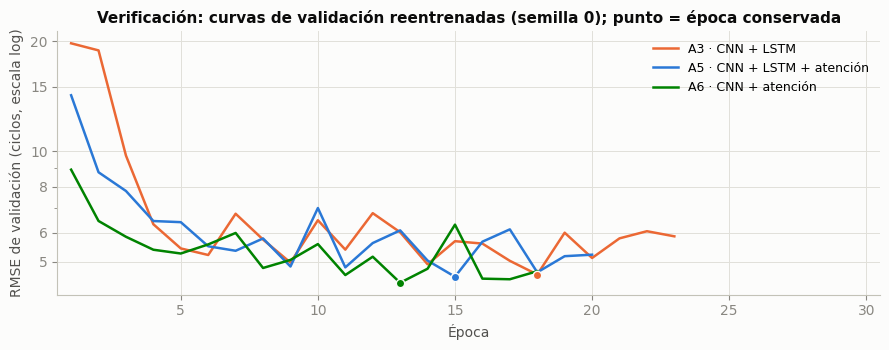

In [14]:
verif = run_many([dict(arch=a, seed=0, base_dir=VERIF_DIR) for a in ("A3", "A5", "A6")],
                 label="  ")

if not SMOKE_TEST:
    rows = []
    for r in verif:
        ref_dir = os.path.join(RUNS_DIR, r["id"])          # misma corrida, copiada de v02
        with open(os.path.join(ref_dir, "run.json"), encoding="utf-8") as fh:
            ref = json.load(fh)
        ref_preds = np.load(os.path.join(ref_dir, "preds.npz"))
        h_new, h_ref = np.array(r["history"]["val_rmse"]), np.array(ref["history"]["val_rmse"])
        rows.append({
            "Arquitectura": r["arch"],
            "Épocas (v02 / ahora)": f"{len(h_ref)} / {len(h_new)}",
            "Mejor época (v02 / ahora)": f"{ref['best_epoch']} / {r['best_epoch']}",
            # Si las longitudes difieren, la diferencia se marca como infinita
            "Dif. historial": (float(np.max(np.abs(h_new - h_ref)))
                               if len(h_new) == len(h_ref) else np.inf),
            "Dif. pred. validación": float(np.max(np.abs(r["val_pred"] - ref_preds["val"]))),
            "Dif. pred. evaluación": float(np.max(np.abs(r["eval_pred"] - ref_preds["eval"]))),
        })
    comp = pd.DataFrame(rows)
    print(comp.to_string(index=False))
    ok = (comp[["Dif. historial", "Dif. pred. validación", "Dif. pred. evaluación"]] == 0).all().all()
    print("\nOK: el reentrenamiento coincide exactamente con v02" if ok
          else "\nERROR: el reentrenamiento difiere de v02, revisar")
    assert ok

# Curvas de las tres corridas reentrenadas, en el eje común de 1 a 30 épocas.
# Cada curva termina donde la detuvo el early stopping; el punto marca la época conservada.
fig, ax = plt.subplots(figsize=(9, 3.6))
for r in verif:
    hist = r["history"]["val_rmse"]
    ax.plot(np.arange(1, len(hist) + 1), hist, color=ARCH_COLORS[r["arch"]], lw=1.8,
            label=ARCH_LABELS[r["arch"]])
    ax.scatter([r["best_epoch"]], [hist[r["best_epoch"] - 1]], s=36, color=ARCH_COLORS[r["arch"]],
               edgecolor=SURFACE, linewidth=1, zorder=3)
ax.set_yscale("log")
ax.yaxis.set_major_locator(mticker.FixedLocator([4, 5, 6, 8, 10, 15, 20, 30]))
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
set_epoch_axis(ax)
ax.set_ylabel("RMSE de validación (ciclos, escala log)")
ax.set_title("Verificación: curvas de validación reentrenadas (semilla 0); punto = época conservada")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

# Etapa 1 — Ablación de arquitecturas con curvas comparables

**Pregunta:** ¿qué aporta cada bloque (convolución, recurrencia, atención) a la
estimación del RUL cerca del fallo, y qué mecanismo de atención conviene llevar a la
etapa siguiente?

**Configuración:** las seis arquitecturas del catálogo (sección 0.8), normalización
global, pérdida MSE y 5 semillas: 30 corridas, reutilizadas de v02 (sección 0.13).

**Criterio de selección (pre-registrado, sección 0.12):** entre las arquitecturas con
atención (A4, A5, A6), la de menor **mediana de RMSE en la zona final** (RUL ≤ 20) en
validación. A3 se mantiene como referencia sin atención.

**Novedad respecto de v02 (Reunión 04):** todas las curvas de aprendizaje se grafican en
un mismo eje de 1 a 30 épocas, y se agrega una tabla de convergencia (en qué época se
conserva cada modelo y cuántas épocas entrenó antes del early stopping).

**Alcance:** solo validación (motores 18 y 20). El conjunto de prueba se presenta en la
etapa 3.

## 1.1 Corridas

In [15]:
STAGE1_ARCHS = ["A1", "A2", "A3", "A4", "A5", "A6"]
ATT_ARCHS = ["A4", "A5", "A6"]          # arquitecturas con atención: entre ellas se elige

# Una corrida por arquitectura y semilla; todas existen en disco, así que solo se cargan
stage1 = run_many([dict(arch=a, seed=s) for a in STAGE1_ARCHS for s in SEEDS], label="  ")
s1_val = records_to_df(stage1, "val")    # métricas de cada corrida sobre validación
s1_val.to_csv(os.path.join(OUT_DIR, "etapa1_val.csv"), index=False, encoding="utf-8-sig")

  A1 · global · alpha=1 · semilla 0 | mejor época  6/11 | caché
  A1 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A1 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A1 · global · alpha=1 · semilla 3 | mejor época  6/11 | caché
  A1 · global · alpha=1 · semilla 4 | mejor época  7/12 | caché
  A2 · global · alpha=1 · semilla 0 | mejor época  8/13 | caché
  A2 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A2 · global · alpha=1 · semilla 2 | mejor época 17/22 | caché
  A2 · global · alpha=1 · semilla 3 | mejor época  9/14 | caché
  A2 · global · alpha=1 · semilla 4 | mejor época  8/13 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · alpha=1 · semilla 4 | mejor época 10/15 | caché
  A4 · global · alpha=1 · semilla 0 | me

## 1.2 Resultados en validación

Primera tabla: mediana [mín. – máx.] sobre las 5 semillas, ordenada por la métrica
principal. Segunda tabla: el RMSE en la zona final de cada semilla. Tercera tabla: el
RMSE en la zona final de cada motor de validación.

In [16]:
# Orden de las arquitecturas: de menor a mayor mediana de RMSE final
_order = s1_val.groupby("arch")["RMSE final"].median().sort_values().index.tolist()

tab1 = summary_table(s1_val, "arch", MAIN_METRICS + ["RMSE intermedia", "RMSE temprana"])
tab1 = tab1.set_index("arch").loc[_order].reset_index()
tab1.insert(1, "Arquitectura", tab1["arch"].map(lambda k: ARCHS[k]["name"]))
tab1.insert(2, "Parámetros", tab1["arch"].map(
    lambda k: f"{int(s1_val[s1_val['arch'] == k]['params'].iloc[0]):,}".replace(",", ".")))
print("Validación — mediana [mín. – máx.] sobre semillas, ordenado por RMSE final")
display(tab1.rename(columns={"arch": "Id"}))

print("\nRMSE en zona final por semilla (validación)")
display(s1_val.pivot(index="seed", columns="arch", values="RMSE final")[_order].round(3))

print("\nRMSE en zona final por motor de validación — mediana [mín. – máx.]")
display(summary_table(s1_val, "arch", ["RMSE final u18", "RMSE final u20"])
        .set_index("arch").loc[_order].reset_index().rename(columns={"arch": "Id"}))

Validación — mediana [mín. – máx.] sobre semillas, ordenado por RMSE final


,Id,Arquitectura,Parámetros,n,RMSE final,Sobreest. media final,Score NASA final,RMSE,Sesgo,RMSE intermedia,RMSE temprana
0,A6,CNN + atención,14.497,5,2.00 [1.77 – 3.02],1.04 [0.80 – 1.48],0.18 [0.14 – 0.25],4.38 [4.35 – 4.91],-0.08 [-0.23 – 1.01],4.44 [3.88 – 5.28],5.75 [5.27 – 5.87]
1,A1,1D-CNN,10.273,5,2.02 [1.80 – 2.39],1.10 [0.91 – 1.24],0.16 [0.14 – 0.20],5.02 [4.80 – 5.53],1.56 [0.87 – 1.69],6.01 [5.16 – 6.29],5.85 [5.48 – 6.60]
2,A2,LSTM,23.617,5,2.07 [1.82 – 2.46],1.38 [0.87 – 1.87],0.18 [0.15 – 0.23],4.58 [4.48 – 4.78],0.91 [-0.06 – 1.89],4.77 [4.13 – 4.94],5.90 [5.53 – 6.05]
3,A4,LSTM + atención,27.841,5,2.17 [1.98 – 2.43],1.31 [1.16 – 1.76],0.18 [0.17 – 0.22],5.00 [4.80 – 5.17],1.78 [1.74 – 1.91],5.61 [5.30 – 5.96],6.01 [5.73 – 6.17]
4,A5,CNN + LSTM + atención,33.249,5,2.18 [1.90 – 2.78],1.52 [0.92 – 1.85],0.19 [0.15 – 0.24],4.89 [4.55 – 5.24],0.95 [0.37 – 2.18],5.60 [4.55 – 6.30],5.81 [5.44 – 6.04]
5,A3,CNN + LSTM,29.025,5,2.60 [2.26 – 2.74],1.89 [0.77 – 1.98],0.24 [0.18 – 0.25],4.93 [4.61 – 5.34],1.56 [0.72 – 1.91],5.55 [4.80 – 6.25],5.76 [5.63 – 6.14]



RMSE en zona final por semilla (validación)


arch,A6,A1,A2,A4,A5,A3
seed,,,,,,
0,2.004,2.016,2.071,2.168,1.901,2.543
1,3.019,1.870,2.149,2.394,2.711,2.738
2,1.781,1.801,2.456,2.425,2.179,2.599
3,1.772,2.316,2.015,1.982,2.779,2.614
4,2.202,2.391,1.823,2.139,2.154,2.262



RMSE en zona final por motor de validación — mediana [mín. – máx.]


,Id,n,RMSE final u18,RMSE final u20
0,A6,5,1.47 [1.18 – 3.28],2.57 [1.92 – 2.80]
1,A1,5,1.55 [1.22 – 1.99],2.44 [2.18 – 2.90]
2,A2,5,1.43 [1.22 – 1.69],2.63 [1.97 – 3.23]
3,A4,5,1.47 [1.27 – 1.64],2.67 [2.52 – 3.21]
4,A5,5,1.84 [1.24 – 2.40],2.88 [2.17 – 3.37]
5,A3,5,1.93 [1.60 – 2.60],3.18 [2.49 – 3.47]


## 1.3 Convergencia

Para cada arquitectura: la época que se conservó (la de menor error de validación), el
número de épocas que alcanzó a entrenar, y cuántas semillas se detuvieron por el límite de
30 épocas y no por el early stopping (es decir, que seguían mejorando cuando se cortó el
entrenamiento). Una mejor época tardía indica que el modelo sigue mejorando por más
tiempo, es decir, que converge más lento.

In [17]:
conv_rows = []
for k in _order:
    recs = [r for r in stage1 if r["arch"] == k]
    best = [r["best_epoch"] for r in recs]               # época conservada de cada semilla
    trained = [r["epochs"] for r in recs]                # épocas entrenadas de cada semilla
    conv_rows.append({
        "Id": k, "Arquitectura": ARCHS[k]["name"],
        "Época conservada": med_range(best, "{:.0f}"),
        "Épocas entrenadas": med_range(trained, "{:.0f}"),
        # Detenida por el límite: entrenó 30 épocas y aún no acumulaba 5 sin mejorar.
        # (Una corrida puede llegar a la época 30 justo cuando se activa el early stopping;
        # esa no cuenta, porque sí se detuvo por falta de mejora.)
        "Detenidas por el límite de 30": sum(t == MAX_EPOCHS and t - b < PATIENCE
                                             for t, b in zip(trained, best)),
        "Segundos por corrida": med_range([r["seconds"] for r in recs], "{:.0f}"),
    })
display(pd.DataFrame(conv_rows))

,Id,Arquitectura,Época conservada,Épocas entrenadas,Detenidas por el límite de 30,Segundos por corrida
0,A6,CNN + atención,16 [6 – 30],21 [11 – 30],1,90 [42 – 121]
1,A1,1D-CNN,7 [6 – 9],12 [11 – 14],0,40 [33 – 44]
2,A2,LSTM,9 [8 – 17],14 [13 – 22],0,57 [53 – 90]
3,A4,LSTM + atención,8 [4 – 10],13 [9 – 15],0,57 [43 – 72]
4,A5,CNN + LSTM + atención,9 [3 – 15],14 [8 – 20],0,66 [36 – 102]
5,A3,CNN + LSTM,9 [5 – 18],14 [10 – 23],0,55 [39 – 90]


## 1.4 Selección del mecanismo de atención

Se aplica el criterio pre-registrado. Además se informa si el rango entre semillas de
la arquitectura elegida se solapa con el de A3: si se solapan, la ventaja sobre la base
sin atención no es nítida con 5 semillas, aunque la mediana sea menor.

In [18]:
_med = s1_val.groupby("arch")["RMSE final"].median()               # mediana por arquitectura
_rng = s1_val.groupby("arch")["RMSE final"].agg(["min", "max"])    # rango por arquitectura
STAGE1_CHOICE = _med[ATT_ARCHS].idxmin()                           # criterio pre-registrado

print("Ranking por mediana de RMSE final (validación):")
for i, k in enumerate(_order, 1):
    mark = "  (elegida)" if k == STAGE1_CHOICE else ("  (referencia sin atención)" if k == "A3" else "")
    print(f"  {i}. {ARCH_LABELS[k]:<28} {_med[k]:.3f}  [{_rng.loc[k, 'min']:.3f} – {_rng.loc[k, 'max']:.3f}]{mark}")

# Dos rangos se solapan salvo que uno termine antes de que empiece el otro
_overlap = not (_rng.loc[STAGE1_CHOICE, "max"] < _rng.loc["A3", "min"]
                or _rng.loc["A3", "max"] < _rng.loc[STAGE1_CHOICE, "min"])
# Comparación semilla a semilla: misma semilla = mismo barajado de los lotes
_n_better = int((s1_val[s1_val["arch"] == STAGE1_CHOICE].set_index("seed")["RMSE final"]
                 < s1_val[s1_val["arch"] == "A3"].set_index("seed")["RMSE final"]).sum())
print(f"\nArquitectura elegida: {ARCH_LABELS[STAGE1_CHOICE]}")
print(f"Rango entre semillas solapado con A3: {'sí' if _overlap else 'no'}")
print(f"Semillas en que supera a A3: {_n_better} de {len(SEEDS)}")

# La decisión se registra junto a los criterios
selection["decisiones"]["etapa_1"] = {
    "arquitectura_elegida": STAGE1_CHOICE,
    "nombre": ARCHS[STAGE1_CHOICE]["name"],
    "mediana_rmse_final_val": round(float(_med[STAGE1_CHOICE]), 4),
    "mediana_rmse_final_val_A3": round(float(_med["A3"]), 4),
    "rango_solapado_con_A3": bool(_overlap),
    "semillas_mejor_que_A3": _n_better,
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

Ranking por mediana de RMSE final (validación):
  1. A6 · CNN + atención          2.004  [1.772 – 3.019]  (elegida)
  2. A1 · 1D-CNN                  2.016  [1.801 – 2.391]
  3. A2 · LSTM                    2.071  [1.823 – 2.456]
  4. A4 · LSTM + atención         2.168  [1.982 – 2.425]
  5. A5 · CNN + LSTM + atención   2.179  [1.901 – 2.779]
  6. A3 · CNN + LSTM              2.599  [2.262 – 2.738]  (referencia sin atención)

Arquitectura elegida: A6 · CNN + atención
Rango entre semillas solapado con A3: sí
Semillas en que supera a A3: 4 de 5


## 1.5 Figuras

### Comparación de arquitecturas

En los paneles a–c cada punto es una semilla, el trazo negro marca la mediana y la línea
horizontal, el rango. El panel d cruza el error con el número de parámetros, para
distinguir el efecto de un bloque del efecto de tener más capacidad.

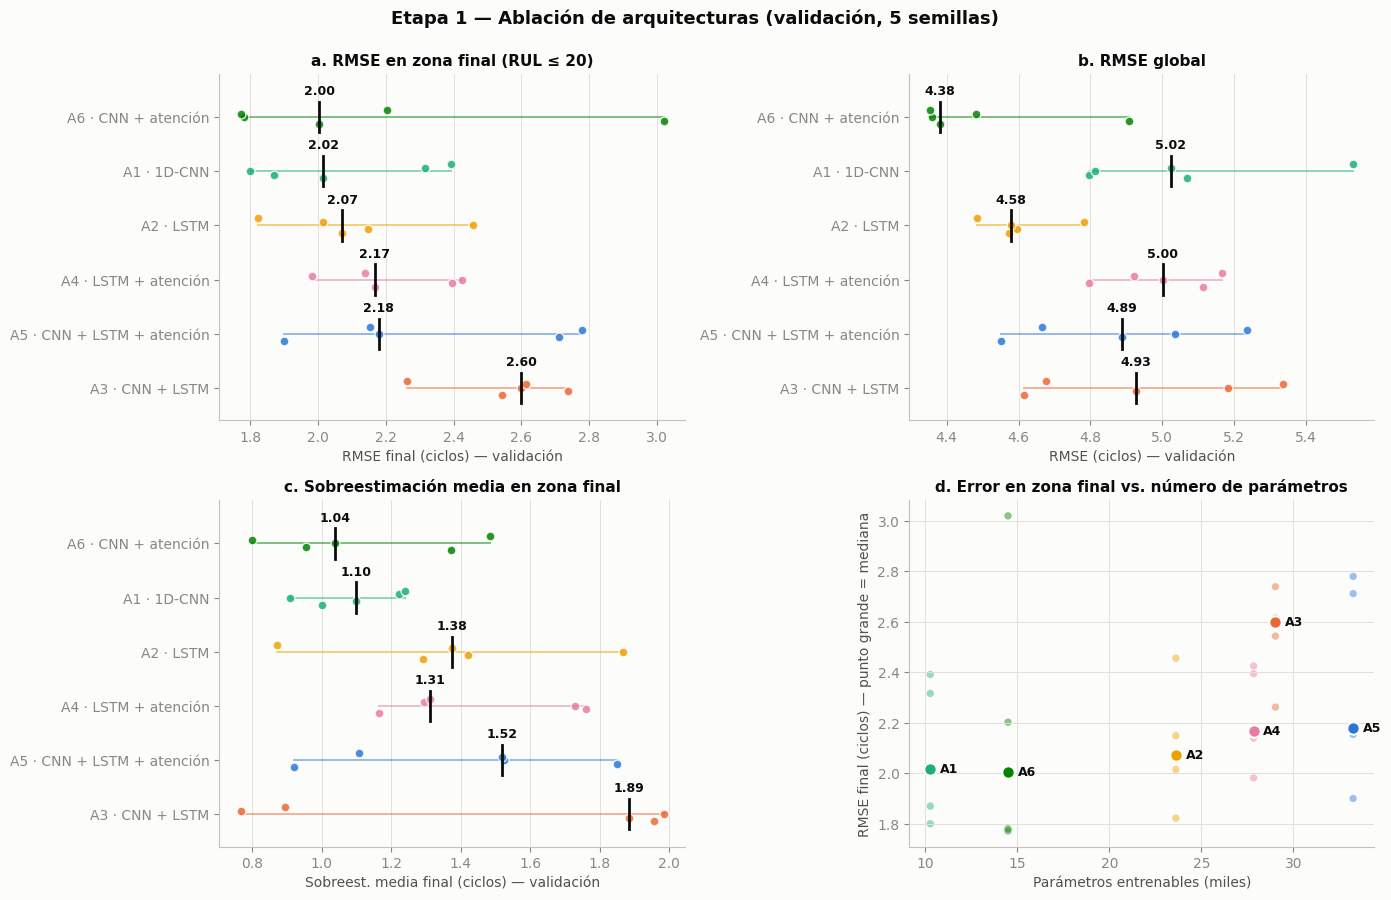

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric, title in (
        (axes[0, 0], "RMSE final", "a. RMSE en zona final (RUL ≤ 20)"),
        (axes[0, 1], "RMSE", "b. RMSE global"),
        (axes[1, 0], "Sobreest. media final", "c. Sobreestimación media en zona final")):
    seed_dotplot(ax, s1_val, metric, _order, labels=ARCH_LABELS)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} (ciclos) — validación")

ax = axes[1, 1]
for k in _order:
    sub = s1_val[s1_val["arch"] == k]
    # Puntos chicos: cada semilla. Punto grande: la mediana de la arquitectura
    ax.scatter(sub["params"] / 1000, sub["RMSE final"], s=28, color=ARCH_COLORS[k], alpha=0.45,
               edgecolor="none")
    ax.scatter(sub["params"].iloc[0] / 1000, sub["RMSE final"].median(), s=80, color=ARCH_COLORS[k],
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(k, (sub["params"].iloc[0] / 1000, sub["RMSE final"].median()), xytext=(7, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9, fontweight="bold")
ax.set_title("d. Error en zona final vs. número de parámetros")
ax.set_xlabel("Parámetros entrenables (miles)")
ax.set_ylabel("RMSE final (ciclos) — punto grande = mediana")

fig.suptitle("Etapa 1 — Ablación de arquitecturas (validación, 5 semillas)",
             fontsize=13, fontweight="bold", color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_ablacion.png"), dpi=160, bbox_inches="tight")
plt.show()

### Curvas de aprendizaje en un eje común de 30 épocas

RMSE de validación por época. Todos los paneles comparten el eje horizontal (1 a 30
épocas) y el vertical, para que se puedan comparar a simple vista. Cada línea tenue es
una semilla y termina donde la detuvo el early stopping; el punto marca la época que se
conservó. La línea gruesa es la mediana entre semillas, hasta la época en que se detuvo
la semilla más corta.

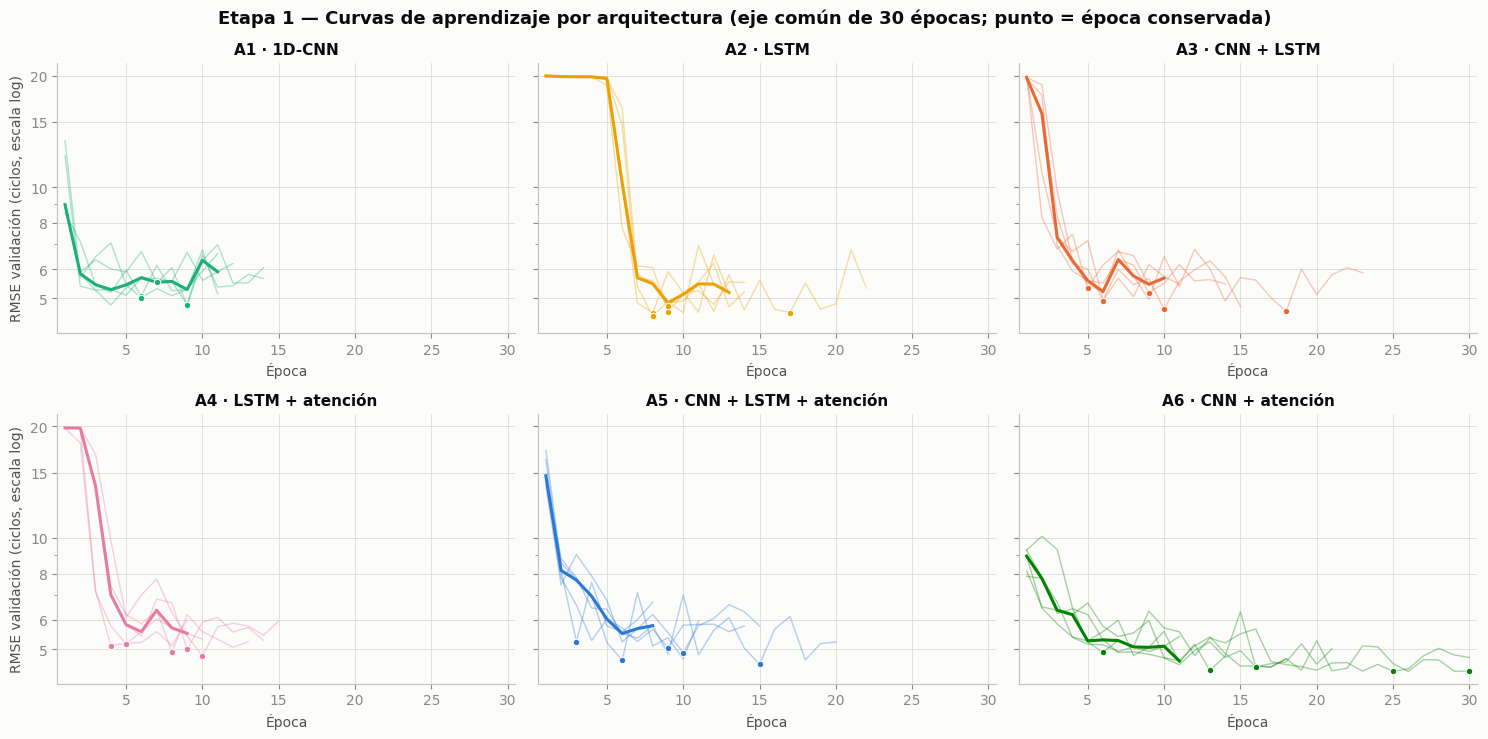

In [20]:
by_arch = {k: [r for r in stage1 if r["arch"] == k] for k in STAGE1_ARCHS}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), STAGE1_ARCHS):
    seed_curves(ax, by_arch[k], "val_rmse", color=ARCH_COLORS[k])
    ax.set_title(ARCH_LABELS[k])
    # Escala logarítmica: el RMSE va de ~20 a ~5 ciclos y la zona de convergencia es la
    # que decide la comparación; en escala lineal quedaría comprimida contra el eje
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.FixedLocator([4, 5, 6, 8, 10, 15, 20, 30]))
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    set_epoch_axis(ax)                              # eje común de 1 a 30 épocas
    # Con sharex, matplotlib oculta los números del eje en la fila superior; se muestran
    # en todos los paneles para leer cada curva sin tener que mirar la fila de abajo
    ax.tick_params(axis="x", labelbottom=True)
for ax in axes[:, 0]:
    ax.set_ylabel("RMSE validación (ciclos, escala log)")
fig.suptitle("Etapa 1 — Curvas de aprendizaje por arquitectura (eje común de 30 épocas; "
             "punto = época conservada)", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_curvas.png"), dpi=160, bbox_inches="tight")
plt.show()

### Trayectorias de RUL en los motores de validación

Para cada ciclo de vuelo se promedian las predicciones de sus ventanas y luego se toma
la mediana entre semillas. Se comparan la línea base simple (A1), la base híbrida sin
atención (A3) y la arquitectura elegida. La franja sombreada es la zona final.

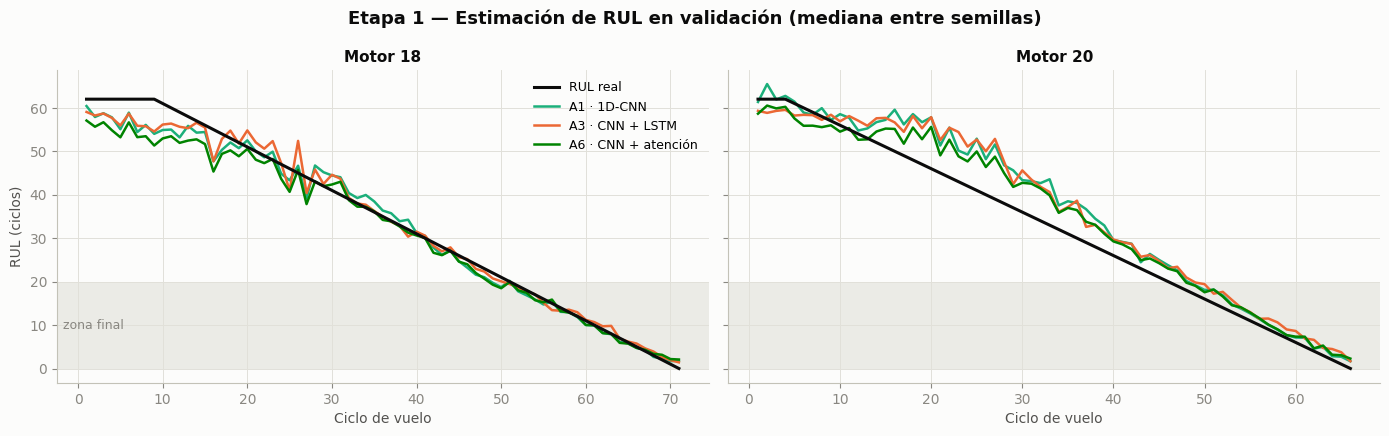

In [21]:
_, _yv, _mv = build_tensors("global", "oficial")["val"]    # RUL real y (motor, ciclo) de cada ventana
_show = list(dict.fromkeys(["A1", "A3", STAGE1_CHOICE]))  # sin repetidos si la elegida fuera A1 o A3
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, u in zip(axes, VAL_UNITS):
    m = _mv[:, 0] == u                                     # ventanas de este motor
    cyc = np.unique(_mv[m, 1])
    true_c = [_yv[m][_mv[m, 1] == c].mean() for c in cyc]  # RUL real promedio por ciclo
    ax.axhspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.plot(cyc, true_c, color=INK, lw=2.2, label="RUL real", zorder=4)
    for k in _show:
        # Promedio por ciclo para cada semilla y, luego, mediana entre semillas
        per_seed = [[r["val_pred"][m][_mv[m, 1] == c].mean() for c in cyc] for r in by_arch[k]]
        ax.plot(cyc, np.median(per_seed, axis=0), color=ARCH_COLORS[k], lw=1.8,
                label=ARCH_LABELS[k], zorder=3)
    ax.set_title(f"Motor {int(u)}")
    ax.set_xlabel("Ciclo de vuelo")
axes[0].set_ylabel("RUL (ciclos)")
axes[0].annotate("zona final", (0.01, FINAL_ZONE / 2), xycoords=("axes fraction", "data"),
                 color=MUTED, fontsize=9, va="center")
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Etapa 1 — Estimación de RUL en validación (mediana entre semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_trayectorias.png"), dpi=160, bbox_inches="tight")
plt.show()

### Pesos de atención

Peso promedio $\alpha_t$ que cada arquitectura con atención asigna a cada uno de los 30
pasos de la ventana, en validación y promediado sobre las semillas. Se separan las
ventanas de la zona final del resto. Un perfil plano en $1/30$ significa que la atención
actúa como un promedio simple; un perfil que cambia entre zonas indica que el modelo
atiende a instantes distintos según la etapa de degradación.

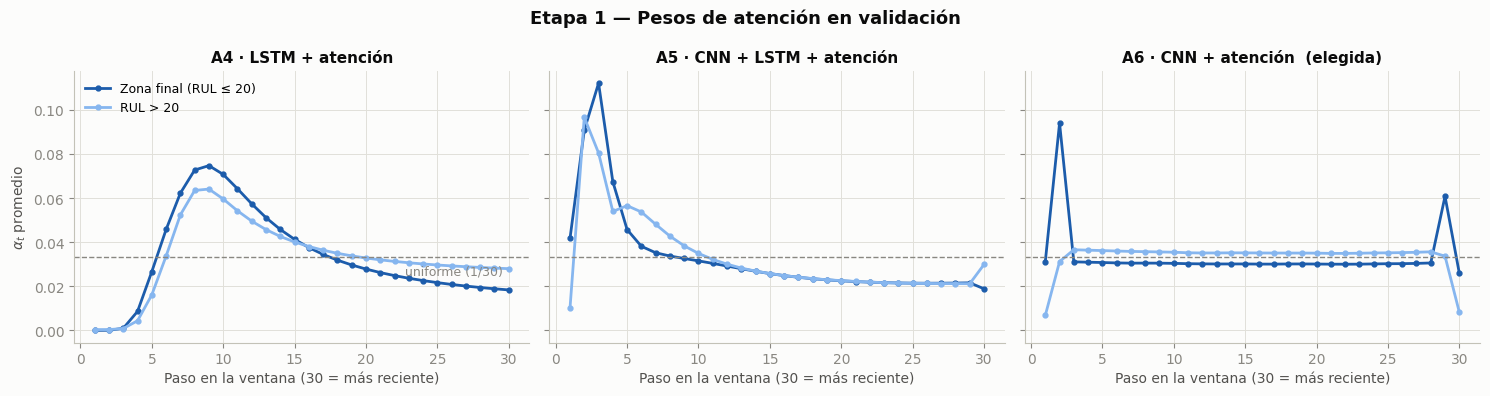

In [22]:
_Xv = build_tensors("global", "oficial")["val"][0]
_fin = _yv <= FINAL_ZONE                                    # ventanas de la zona final
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
steps = np.arange(1, WINDOW_SIZE + 1)
for ax, k in zip(axes, ATT_ARCHS):
    # Pesos de cada semilla, de forma (N ventanas, 30), promediados entre semillas
    W = np.mean([predict(load_model(r), _Xv, collect_weights=True)[1] for r in by_arch[k]], axis=0)
    ax.plot(steps, W[_fin].mean(axis=0), color="#1c5cab", lw=2, marker="o", ms=3.5,
            label=f"Zona final (RUL ≤ {FINAL_ZONE:g})")
    ax.plot(steps, W[~_fin].mean(axis=0), color="#86b6ef", lw=2, marker="o", ms=3.5,
            label=f"RUL > {FINAL_ZONE:g}")
    ax.axhline(1 / WINDOW_SIZE, color=MUTED, lw=1, ls="--")   # peso de un promedio uniforme
    ax.set_title(ARCH_LABELS[k] + ("  (elegida)" if k == STAGE1_CHOICE else ""))
    ax.set_xlabel("Paso en la ventana (30 = más reciente)")
axes[0].set_ylabel(r"$\alpha_t$ promedio")
axes[0].annotate("uniforme (1/30)", (WINDOW_SIZE, 1 / WINDOW_SIZE), xytext=(-4, -13),
                 textcoords="offset points", ha="right", color=MUTED, fontsize=9)
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Etapa 1 — Pesos de atención en validación", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_atencion.png"), dpi=160, bbox_inches="tight")
plt.show()

## 1.6 Discusión

Los resultados son exactamente los de v02 (mismas corridas). Lo nuevo es la lectura de
la convergencia con las curvas en un eje común.

### Cinco de las seis arquitecturas son indistinguibles en la zona final

| Id | Arquitectura | Parámetros | RMSE final (validación) |
|---|---|---|---|
| A6 | CNN + atención | 14.497 | 2,00 [1,77 – 3,02] |
| A1 | 1D-CNN | 10.273 | 2,02 [1,80 – 2,39] |
| A2 | LSTM | 23.617 | 2,07 [1,82 – 2,46] |
| A4 | LSTM + atención | 27.841 | 2,17 [1,98 – 2,43] |
| A5 | CNN + LSTM + atención | 33.249 | 2,18 [1,90 – 2,78] |
| A3 | CNN + LSTM | 29.025 | 2,60 [2,26 – 2,74] |

Las medianas de A6, A1, A2, A4 y A5 caben en 0,18 ciclos y sus rangos se solapan. Solo
A3 se separa, hacia peor: su mejor semilla (2,26) es peor que la mediana de todas las
demás. Más parámetros no implican menos error: A1, la más pequeña, empata con las mejores.

### El efecto de la atención depende de la arquitectura base

| Par (solo cambia la agregación) | RMSE final | RMSE global |
|---|---|---|
| CNN → CNN + atención (A1 → A6) | 2,02 → 2,00 | 5,02 → 4,38 |
| LSTM → LSTM + atención (A2 → A4) | 2,07 → 2,17 | 4,58 → 5,00 |
| CNN + LSTM → con atención (A3 → A5) | 2,60 → 2,18 | 4,93 → 4,89 |

### Convergencia: A6 converge más lento

Con las curvas en el mismo eje se ve lo que se comentó en la Reunión 04. A6 conserva
su mejor época en la 16 (mediana), frente a las épocas 7 a 9 del resto, y entrena 21
épocas (mediana) frente a 12 a 14. Una de sus semillas seguía mejorando cuando se
alcanzó el límite de 30 épocas. En la práctica, A6 sigue reduciendo el error por más
tiempo que las demás, a costa de más tiempo de cómputo (90 s por corrida, frente a 40 a
66 s).

Dos consecuencias:

- **El resultado de A6 podría estar subestimado.** La semilla que se detuvo por el límite
  no terminó de converger, así que su error podría ser algo menor con más épocas.
- **Las LSTM sin convolución (A2 y A4) tardan en arrancar.** Durante las primeras 4 a 5
  épocas su error se mantiene cerca de 20 ciclos, lo que corresponde a predecir casi el
  mismo valor para todas las ventanas, y luego cae bruscamente. Las arquitecturas con
  convolución empiezan a aprender desde la primera época.

Lo que estas curvas no permiten afirmar es *por qué* A6 converge más lento: eso
requeriría analizar los gradientes durante el entrenamiento, y aquí no se midieron.

### Pesos de atención

En A6 los pesos son casi uniformes (cerca de $1/30$), con picos en los pasos 2 y 29.
Esos picos coinciden con los bordes de la ventana, donde las dos convoluciones (kernel 3)
operan sobre el relleno de ceros, por lo que probablemente reflejan un efecto de borde.
Es decir, A6 se comporta en la práctica como un promedio temporal, lo que explica que
empate con A1. A4 y A5 sí muestran perfiles no uniformes.

### Selección

Con el criterio pre-registrado, **A6 (CNN + atención) pasa a la etapa 2**, con A3 como
referencia sin atención. Salvedades: su ventaja sobre A1 es de 0,01 ciclos, tiene el rango
más amplio por una semilla atípica (3,02) y su atención es casi uniforme. Frente a A3 el
rango se solapa, pero A6 es mejor en 4 de las 5 semillas.

### Limitación de la ablación

Los pares de la tabla anterior difieren solo en la agregación. Las comparaciones entre
extractores no son estrictas: A1 y A6 tienen una segunda convolución (32 → 64 canales)
que A3 y A5 no tienen, y la agregación sin atención es el promedio en A1 y el último
estado en A2 y A3.

# Etapa 2 — Pérdida asimétrica

**Pregunta:** ¿se reduce la sobreestimación cerca del fallo si el entrenamiento
penaliza más sobreestimar que subestimar?

## 2.1 El método, su nombre y sus referencias

**Nombre.** La pérdida usada se llama **pérdida cuadrática asimétrica** (*asymmetric
squared error loss*, Efron, 1991). Es la función que minimiza la **regresión por
expectiles**, también llamada mínimos cuadrados asimétricos (*asymmetric least squares*,
Newey y Powell, 1987).

**Definición.** Con $d = \hat{y} - y$ (positivo = sobreestimación):

$$\mathcal{L}_\alpha = \frac{1}{N}\sum_i w(d_i)\, d_i^2, \qquad
w(d) = \begin{cases} \alpha & d > 0 \\ 1 & d \le 0 \end{cases}$$

Con $\alpha = 1$ es el error cuadrático medio (MSE). Con $\alpha > 1$, sobreestimar pesa
$\alpha$ veces más que subestimar.

**Qué estima el modelo.** Con el MSE, el valor que minimiza la pérdida es la **media**
del RUL dadas las entradas. Con $\mathcal{L}_\alpha$ es el **expectil** de nivel
$\tau = 1/(1+\alpha)$: un valor que queda por debajo de la media, es decir, una
estimación conservadora. Newey y Powell escriben la pérdida con un peso $\tau$ para los
residuos positivos ($y - \hat{y} > 0$, subestimación) y $1-\tau$ para los negativos; igualar
el cociente de esos pesos a $\alpha$ da $\tau = 1/(1+\alpha)$.

| α | Expectil τ | Sobreestimar 5 ciclos cuesta lo mismo que subestimar |
|---|---|---|
| 1 (= MSE) | 0,50 | 5,0 ciclos |
| 2 | 0,33 | 7,1 ciclos |
| 4 | 0,20 | 10,0 ciclos |

**Referencias verificadas:**

- Newey, W. K. y Powell, J. L. (1987). Asymmetric Least Squares Estimation and Testing.
  *Econometrica*, 55(4), 819–847. https://doi.org/10.2307/1911031 — definición de la
  regresión por expectiles.
- Efron, B. (1991). Regression percentiles using asymmetric squared error loss.
  *Statistica Sinica*, 1(1), 93–125 — nombre de la pérdida.
- Saxena, A., Goebel, K., Simon, D. y Eklund, N. (2008). Damage propagation modeling for
  aircraft engine run-to-failure simulation. *2008 International Conference on
  Prognostics and Health Management*, Denver. https://doi.org/10.1109/PHM.2008.4711414
  — origen del score NASA y de la idea de penalizar más la sobreestimación en RUL.

**Antecedentes en pronóstico de RUL** (motores turbofán, C-MAPSS):

- Peringal, A., Mohiuddin, M. B., Haddad, A. G. y Muthusamy, P. K. (2025). Reliable
  Prediction of Remaining Useful Life for Aircraft Engines: An LSTM-Based Approach with
  Conservative Loss Function. *AIAA SciTech 2025 Forum*. https://doi.org/10.2514/6.2025-1909
  — LSTM con una pérdida modificada que penaliza la sobreestimación. No se pudo consultar
  la forma exacta de su pérdida.
- Abdullah, M. E. B. (2026). Asymmetric-Loss-Guided Hybrid CNN-BiLSTM-Attention Model for
  Industrial RUL Prediction with Interpretable Failure Heatmaps. *arXiv:2604.13459*
  (preprint, sin revisión por pares) — CNN + BiLSTM + atención de Bahdanau entrenada con
  la función exponencial del score NASA como pérdida.

En la búsqueda realizada no se encontraron trabajos que apliquen la regresión por
expectiles al pronóstico de RUL. La búsqueda no fue exhaustiva, así que la afirmación debe
formularse con esa cautela.

## 2.2 Configuración y criterio

La arquitectura elegida en la etapa 1, con normalización global, α ∈ {1, 2, 4} y 5
semillas (corridas de v02). El early stopping usa $\sqrt{\mathcal{L}_\alpha}$ en
validación: detener por RMSE elegiría la época con menos sesgo conservador y anularía el
efecto de la pérdida.

**Criterio (pre-registrado, sección 0.12):** el α que minimiza la mediana del **score NASA
en la zona final** en validación.

In [23]:
STAGE2_ALPHAS = [1.0, 2.0, 4.0]
ALPHA_LABELS = {a: f"α = {a:g}" + (" (MSE)" if a == 1 else "") for a in STAGE2_ALPHAS}
# Rampa de un solo tono: más oscuro = pérdida más asimétrica
ALPHA_COLORS = {ALPHA_LABELS[a]: c for a, c in zip(STAGE2_ALPHAS, ["#86b6ef", "#2a78d6", "#104281"])}

# Una corrida por α y semilla, todas con la arquitectura elegida y normalización global
stage2 = run_many([dict(arch=STAGE1_CHOICE, norm="global", alpha=a, seed=s)
                   for a in STAGE2_ALPHAS for s in SEEDS], label="  ")
s2_val = records_to_df(stage2, "val")
s2_val["cfg"] = s2_val["alpha"].map(ALPHA_LABELS)        # etiqueta legible para tablas y figuras
s2_val.to_csv(os.path.join(OUT_DIR, "etapa2_val.csv"), index=False, encoding="utf-8-sig")

  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · alpha=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · alpha=1 · semilla 4 | mejor época 30/30 | caché
  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · alpha=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
  A6 · global · alpha=4 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=4 · semilla 1 | mejor época  8/13 | caché
  A6 · global · alpha=4 · semilla 2 | mejor época  7/12 | caché
  A6 · global · alpha=4 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=4 · semilla 4 | mejor época 15/20 | caché
-> 15 corridas en 0.0 min (15 desde cach

## 2.3 Resultados en validación y selección de α

In [24]:
print(f"Configuración: {ARCH_LABELS[STAGE1_CHOICE]} · normalización global")
print("Validación — mediana [mín. – máx.] sobre semillas")
display(summary_table(s2_val, "cfg", ["Score NASA final", "RMSE final", "Sobreest. media final",
                                      "% sobreest. final", "RMSE", "Sesgo",
                                      "RMSE intermedia", "RMSE temprana"]))

print("\nScore NASA en zona final por semilla (validación)")
display(s2_val.pivot(index="seed", columns="cfg", values="Score NASA final")
        [[ALPHA_LABELS[a] for a in STAGE2_ALPHAS]].round(3))

_m2 = s2_val.groupby("alpha")["Score NASA final"].median()
STAGE2_CHOICE = float(_m2.idxmin())                       # criterio pre-registrado
_base = s2_val[s2_val["alpha"] == 1.0].set_index("seed")  # referencia: MSE
print("\nMediana del score NASA final (validación):")
for a in STAGE2_ALPHAS:
    sub = s2_val[s2_val["alpha"] == a].set_index("seed")
    # Comparación semilla a semilla contra el MSE
    vs = "" if a == 1.0 else (f" | mejor que MSE en {int((sub['Score NASA final'] < _base['Score NASA final']).sum())}"
                              f" de {len(SEEDS)} semillas")
    print(f"   {ALPHA_LABELS[a]:<12} {_m2[a]:.4f}{vs}{'  (elegido)' if a == STAGE2_CHOICE else ''}")

selection["decisiones"]["etapa_2"] = {
    "alpha_elegido": STAGE2_CHOICE,
    "arquitectura": STAGE1_CHOICE,
    "mediana_score_nasa_final_val": {f"{a:g}": round(float(_m2[a]), 4) for a in STAGE2_ALPHAS},
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

Configuración: A6 · CNN + atención · normalización global
Validación — mediana [mín. – máx.] sobre semillas


,cfg,n,Score NASA final,RMSE final,Sobreest. media final,% sobreest. final,RMSE,Sesgo,RMSE intermedia,RMSE temprana
0,α = 1 (MSE),5,0.18 [0.14 – 0.25],2.00 [1.77 – 3.02],1.04 [0.80 – 1.48],60.94 [45.40 – 76.27],4.38 [4.35 – 4.91],-0.08 [-0.23 – 1.01],4.44 [3.88 – 5.28],5.75 [5.27 – 5.87]
1,α = 2,5,0.14 [0.13 – 0.17],1.83 [1.60 – 2.17],0.77 [0.62 – 0.87],48.12 [45.57 – 62.82],4.53 [4.43 – 4.77],-0.93 [-1.53 – -0.21],4.02 [3.46 – 4.60],5.97 [5.72 – 6.83]
2,α = 4,5,0.17 [0.12 – 0.19],2.17 [1.63 – 2.60],0.45 [0.32 – 0.59],36.63 [25.90 – 41.64],5.30 [4.76 – 5.35],-2.22 [-2.32 – -1.55],3.89 [3.40 – 4.93],7.34 [6.52 – 7.59]



Score NASA en zona final por semilla (validación)


cfg,α = 1 (MSE),α = 2,α = 4
seed,,,
0,0.176,0.139,0.147
1,0.249,0.165,0.176
2,0.147,0.126,0.190
3,0.140,0.129,0.122
4,0.191,0.169,0.169



Mediana del score NASA final (validación):
   α = 1 (MSE)  0.1756
   α = 2        0.1390 | mejor que MSE en 5 de 5 semillas  (elegido)
   α = 4        0.1687 | mejor que MSE en 4 de 5 semillas


## 2.4 Comprobación de la interpretación por expectiles

Si el modelo entrenado con α realmente estima el expectil de nivel $1/(1+\alpha)$, en el
óptimo se cumple la condición de equilibrio de la regresión por expectiles:

$$\alpha \cdot \mathbb{E}[\max(\hat{y} - y, 0)] = \mathbb{E}[\max(y - \hat{y}, 0)]$$

Es decir, la subestimación media debe ser α veces la sobreestimación media. Se obtiene
derivando $\mathcal{L}_\alpha$ respecto de la predicción e igualando a cero.

La condición rige exactamente sobre los datos de entrenamiento y en el óptimo. Aquí se
mide en validación, con motores distintos y un modelo detenido por early stopping, así que
solo se espera que el cociente crezca con α en la dirección correcta, no que coincida
exactamente.

In [25]:
_, _y2, _ = build_tensors("global", "oficial")["val"]
rows = []
for a in STAGE2_ALPHAS:
    ratios = []
    for r in (r for r in stage2 if r["alpha"] == a):
        d = r["val_pred"] - _y2                               # error con signo
        over = np.mean(np.clip(d, 0, None))                   # sobreestimación media
        under = np.mean(np.clip(-d, 0, None))                 # subestimación media
        ratios.append(under / over)
    rows.append({"α": f"{a:g}", "Cociente esperado (= α)": f"{a:g}",
                 "Subestimación / sobreestimación (validación)": med_range(ratios)})
display(pd.DataFrame(rows))

,α,Cociente esperado (= α),Subestimación / sobreestimación (validación)
0,1,1,1.05 [0.53 – 1.15]
1,2,2,1.75 [1.14 – 2.51]
2,4,4,3.53 [2.52 – 3.92]


## 2.5 Figuras

En los paneles a–c cada punto es una semilla y el trazo negro marca la mediana. El panel d
muestra **dónde** actúa la pérdida: el error medio en función del RUL real, reuniendo las 5
semillas.

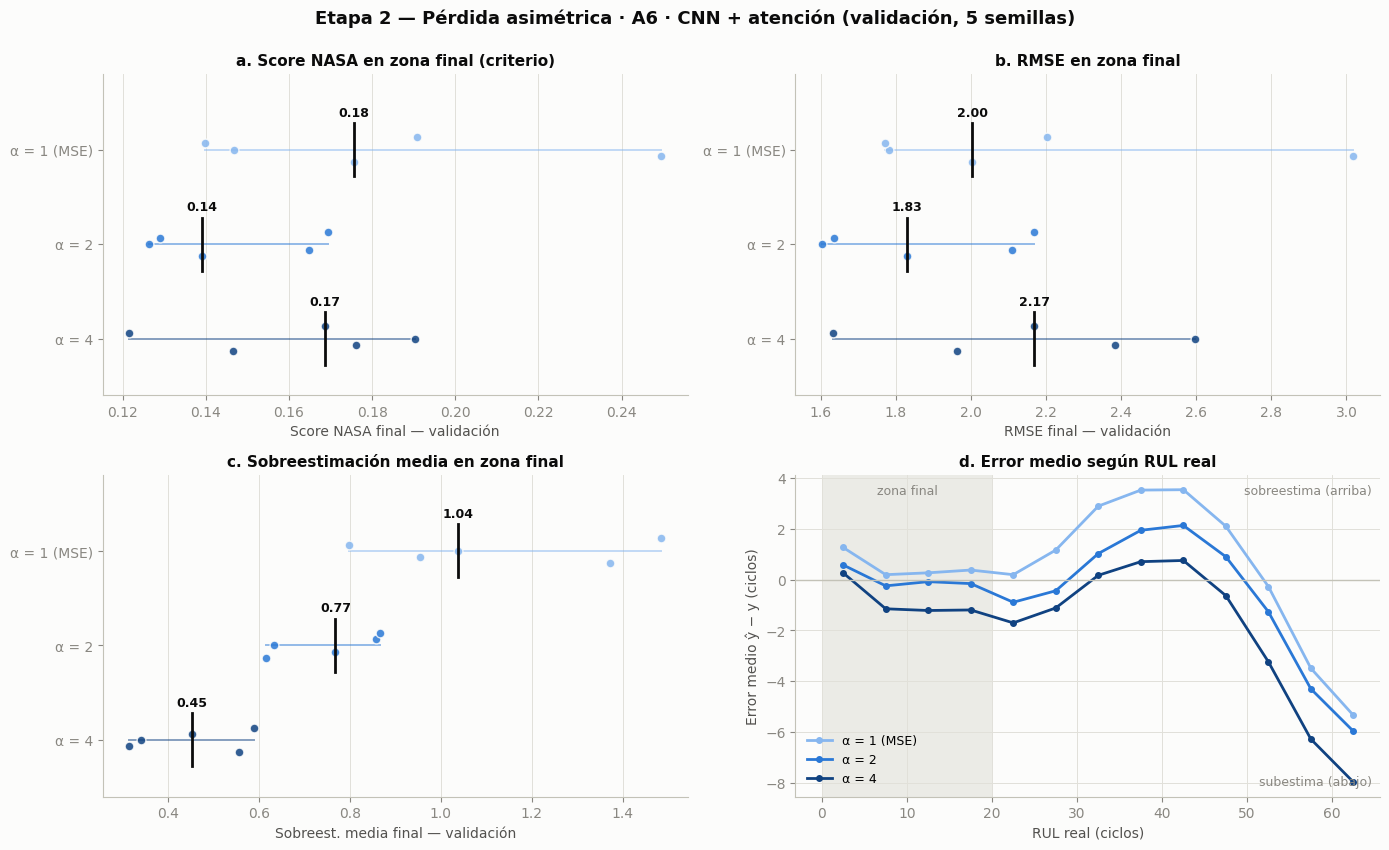

In [26]:
_alpha_cfgs = [ALPHA_LABELS[a] for a in STAGE2_ALPHAS]
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, metric, title in ((axes[0, 0], "Score NASA final", "a. Score NASA en zona final (criterio)"),
                          (axes[0, 1], "RMSE final", "b. RMSE en zona final"),
                          (axes[1, 0], "Sobreest. media final", "c. Sobreestimación media en zona final")):
    seed_dotplot(ax, s2_val, metric, _alpha_cfgs, group_col="cfg", colors=ALPHA_COLORS)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} — validación")

# Panel d: error medio por tramos de 5 ciclos de RUL real
ax = axes[1, 1]
edges = np.arange(0, RUL_MAX + 5, 5)                      # bordes de los tramos de RUL
centers = (edges[:-1] + edges[1:]) / 2
ax.axvspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
for a in STAGE2_ALPHAS:
    # Errores de las 5 semillas concatenados; el RUL real se repite una vez por semilla
    d = np.concatenate([r["val_pred"] - _y2 for r in stage2 if r["alpha"] == a])
    yt = np.tile(_y2, len(SEEDS))
    idx = np.clip(np.digitize(yt, edges) - 1, 0, len(centers) - 1)   # tramo de cada muestra
    ax.plot(centers, [d[idx == k].mean() if np.any(idx == k) else np.nan for k in range(len(centers))],
            color=ALPHA_COLORS[ALPHA_LABELS[a]], lw=2, marker="o", ms=4, label=ALPHA_LABELS[a])
ax.axhline(0, color=AXIS, lw=1)
ax.annotate("zona final", (FINAL_ZONE / 2, 1), xycoords=("data", "axes fraction"), xytext=(0, -14),
            textcoords="offset points", ha="center", color=MUTED, fontsize=9)
ax.annotate("sobreestima (arriba)", (1, 1), xycoords="axes fraction", xytext=(-6, -14),
            textcoords="offset points", ha="right", color=MUTED, fontsize=9)
ax.annotate("subestima (abajo)", (1, 0), xycoords="axes fraction", xytext=(-6, 8),
            textcoords="offset points", ha="right", color=MUTED, fontsize=9)
ax.set_title("d. Error medio según RUL real")
ax.set_xlabel("RUL real (ciclos)")
ax.set_ylabel("Error medio ŷ − y (ciclos)")
ax.legend(loc="lower left", fontsize=9)

fig.suptitle(f"Etapa 2 — Pérdida asimétrica · {ARCH_LABELS[STAGE1_CHOICE]} (validación, 5 semillas)",
             fontsize=13, fontweight="bold", color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa2_perdida_asimetrica.png"), dpi=160, bbox_inches="tight")
plt.show()

### Trayectorias en la zona final

Últimos 30 ciclos de cada motor de validación. Para cada ciclo se promedian sus ventanas
y luego se toma la mediana entre semillas.

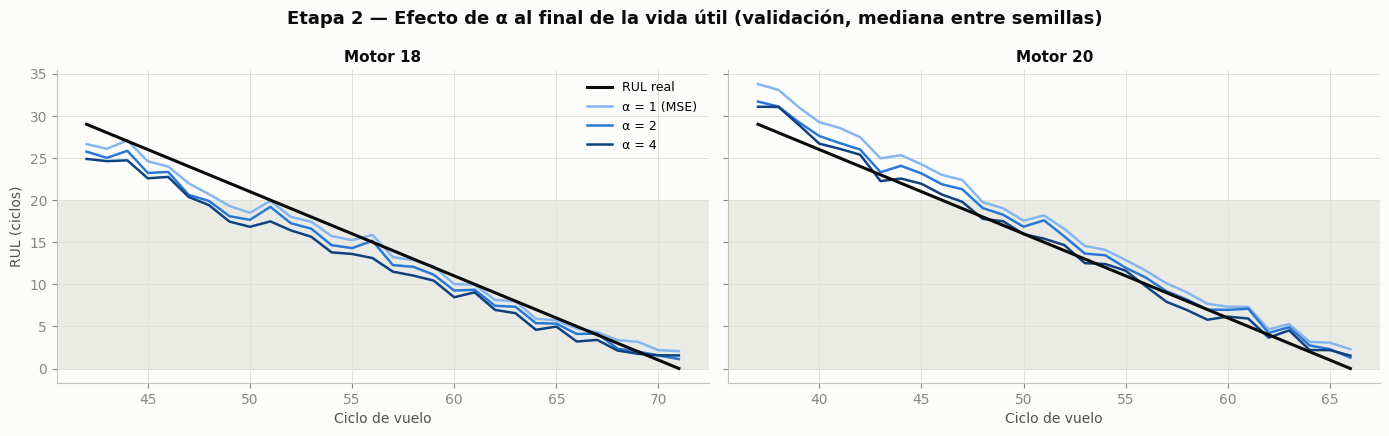

In [27]:
_, _y2, _m2v = build_tensors("global", "oficial")["val"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, u in zip(axes, VAL_UNITS):
    m = _m2v[:, 0] == u
    cyc = np.unique(_m2v[m, 1])
    cyc = cyc[cyc > cyc.max() - 30]                           # solo los últimos 30 ciclos
    ax.axhspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.plot(cyc, [_y2[m][_m2v[m, 1] == c].mean() for c in cyc], color=INK, lw=2.2,
            label="RUL real", zorder=4)
    for a in STAGE2_ALPHAS:
        per_seed = [[r["val_pred"][m][_m2v[m, 1] == c].mean() for c in cyc]
                    for r in stage2 if r["alpha"] == a]
        ax.plot(cyc, np.median(per_seed, axis=0), color=ALPHA_COLORS[ALPHA_LABELS[a]], lw=1.8,
                label=ALPHA_LABELS[a], zorder=3)
    ax.set_title(f"Motor {int(u)}")
    ax.set_xlabel("Ciclo de vuelo")
axes[0].set_ylabel("RUL (ciclos)")
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Etapa 2 — Efecto de α al final de la vida útil (validación, mediana entre semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa2_trayectorias.png"), dpi=160, bbox_inches="tight")
plt.show()

## 2.6 Discusión

### Resultados en validación (A6 · CNN + atención, normalización global)

| Métrica | α = 1 (MSE) | **α = 2** | α = 4 |
|---|---|---|---|
| Score NASA final (criterio) | 0,18 [0,14 – 0,25] | **0,14** [0,13 – 0,17] | 0,17 [0,12 – 0,19] |
| RMSE final | 2,00 [1,77 – 3,02] | **1,83** [1,60 – 2,17] | 2,17 [1,63 – 2,60] |
| Sobreestimación media final | 1,04 | 0,77 | **0,45** |
| % sobreestimación final | 60,9 % | 48,1 % | **36,6 %** |
| RMSE global | **4,38** | 4,53 | 5,30 |
| RMSE zona temprana (> 40) | **5,75** | 5,97 | 7,34 |

Con el criterio pre-registrado se elige **α = 2**, igual que en v02. Frente al MSE, reduce
el score NASA final en las 5 de 5 semillas (−21 % en la mediana), el RMSE final en 5 de 5
(2,00 → 1,83) y la sobreestimación media en la zona final en un 26 %. El costo es un
aumento leve del error al inicio de la vida útil (zona temprana 5,75 → 5,97), donde el
modelo pasa a subestimar: anticipa una inspección, que es el error barato. α = 4 resulta
demasiado conservador: subestima en la zona final y pierde precisión.

### La interpretación por expectiles se sostiene en los datos

La condición de equilibrio de la sección 2.4 predice que la subestimación media sea α
veces la sobreestimación media. Medido en validación:

| α | Cociente esperado | Cociente medido (mediana [mín. – máx.]) |
|---|---|---|
| 1 | 1 | 1,05 [0,53 – 1,15] |
| 2 | 2 | 1,75 [1,14 – 2,51] |
| 4 | 4 | 3,53 [2,52 – 3,92] |

El cociente crece con α y queda cerca del valor teórico, algo por debajo en α = 2 y α = 4.
La diferencia es esperable: la condición rige sobre los datos de entrenamiento y en el
óptimo, mientras que aquí se mide en motores de validación con un modelo detenido por
early stopping. Lo importante para la defensa es que el modelo se comporta como predice la
teoría: **α controla de forma predecible cuánto más conservadora es la estimación.**

### Cómo se sitúa frente a la literatura

Penalizar la sobreestimación en el pronóstico de RUL tiene antecedentes: el score NASA
(Saxena et al., 2008) se diseñó con esa asimetría, Peringal et al. (2025) entrenan una LSTM
con una pérdida conservadora y Abdullah (2026) usa la propia función exponencial del score
NASA como pérdida. Lo que distingue a este trabajo es usar la **pérdida cuadrática
asimétrica de la regresión por expectiles**, que da una interpretación estadística
precisa de lo que estima el modelo (el expectil τ = 1/(1+α)) con un solo parámetro. En la
búsqueda realizada no se encontró esta aplicación en pronóstico de RUL.

# Etapa 3 — Validación cruzada y evaluación final

**Pregunta:** ¿la ventaja de la configuración final se mantiene en motores distintos de
los dos de validación, o depende de la partición elegida?

Se comparan dos configuraciones:

| | Arquitectura | Normalización | Pérdida | Origen |
|---|---|---|---|---|
| **Final** | elegida en la etapa 1 | global | α elegido en la etapa 2 | este trabajo |
| **Base** | A3 · CNN + LSTM | global | MSE (α = 1) | v01 |

**Validación cruzada dejando un motor fuera.** Cada uno de los 6 motores de desarrollo se
evalúa una vez. En cada fold, el motor siguiente de la lista se usa como validación para
el early stopping y los 4 restantes para entrenar. La normalización se reajusta en cada
fold con solo sus motores de entrenamiento, para no filtrar información. Se usan 3
semillas por fold: 6 folds × 2 configuraciones × 3 semillas = 36 corridas (de v02).

**Limitaciones declaradas:**

- El umbral PwL (62 ciclos) se mantiene fijo en todos los folds para que las etiquetas
  sean comparables. Se calculó con los motores 2, 5, 10 y 16, así que en los folds que
  evalúan uno de ellos el umbral depende levemente de ese mismo motor.
- Los 6 motores de desarrollo vuelan la misma clase (`Fc = 3`): la validación cruzada mide
  la variabilidad entre motores, no el cambio hacia otras clases de vuelo.

No hay selección en esta etapa: los resultados se reportan **por motor**.

## 3.1 Folds

In [28]:
CV_UNITS = [2.0, 5.0, 10.0, 16.0, 18.0, 20.0]   # los 6 motores de desarrollo
CV_SEEDS = SEEDS[:3]                             # 3 semillas por fold
FINAL_CFG = dict(arch=STAGE1_CHOICE, norm="global", alpha=STAGE2_CHOICE)
BASE_CFG = dict(arch="A3", norm="global", alpha=1.0)
assert FINAL_CFG != BASE_CFG
CFG_LABELS = {"final": f"Final · {STAGE1_CHOICE} + global + α = {STAGE2_CHOICE:g}",
              "base": "Base · A3 + global + MSE"}
CFG_COLORS = {"final": "#2a78d6", "base": ARCH_COLORS["A3"]}

rows = []
for k, u in enumerate(CV_UNITS):
    v = CV_UNITS[(k + 1) % len(CV_UNITS)]        # validación: el motor siguiente (circular)
    tr = [x for x in CV_UNITS if x not in (u, v)]
    # Cada fold se registra como una partición más; build_tensors la usa igual que la oficial
    SPLITS[f"cv_u{int(u)}"] = {"name": f"cv_u{int(u)}", "train": tr, "val": [v], "eval": [u]}
    rows.append({"Fold": k + 1, "Evaluación": int(u), "Validación": int(v),
                 "Entrenamiento": ", ".join(str(int(x)) for x in tr)})
print(pd.DataFrame(rows).to_string(index=False))


def _cfg_name(r):
    """Devuelve 'final' o 'base' según la configuración de la fila."""
    keys = ("arch", "norm", "alpha")
    return "final" if all(r[k] == FINAL_CFG[k] for k in keys) else "base"


stage3 = run_many([dict(**cfg, seed=s, split=f"cv_u{int(u)}")
                   for u in CV_UNITS for cfg in (FINAL_CFG, BASE_CFG) for s in CV_SEEDS], label="  ")
cv_df = records_to_df(stage3, "eval")           # métricas sobre el motor evaluado en cada fold
cv_df["unidad"] = cv_df["split"].str.replace("cv_u", "").astype(int)
cv_df["config"] = cv_df.apply(_cfg_name, axis=1)
cv_df.to_csv(os.path.join(OUT_DIR, "etapa3_validacion_cruzada.csv"), index=False, encoding="utf-8-sig")

 Fold  Evaluación  Validación  Entrenamiento
    1           2           5 10, 16, 18, 20
    2           5          10  2, 16, 18, 20
    3          10          16   2, 5, 18, 20
    4          16          18   2, 5, 10, 20
    5          18          20   2, 5, 10, 16
    6          20           2  5, 10, 16, 18
  A6 · global · alpha=2 · semilla 0 | mejor época 13/18 | caché


  A6 · global · alpha=2 · semilla 1 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época  1/ 6 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  6/11 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época  9/14 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 16/21 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 11/16 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  4/ 9 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época 10/15 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 10/15 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 14/19 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época  8/13 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  5/10 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época  9/14 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 10/15 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 14/19 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época 11/16 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época 11/16 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 14/19 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché


  A6 · global · alpha=2 · semilla 0 | mejor época 22/27 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 14/19 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época  7/12 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época 11/16 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  6/11 | caché
-> 36 corridas en 0.0 min (36 desde caché)


## 3.2 Resultados por motor

Cada celda es la mediana [mín. – máx.] sobre las 3 semillas del fold en que ese motor fue
evaluado.

In [29]:
CV_METRICS = ["RMSE final", "Score NASA final", "Sobreest. media final", "RMSE", "Sesgo"]
for metric in CV_METRICS:
    # Filas: motor; columnas: configuración
    tab = (cv_df.groupby(["unidad", "config"])[metric].apply(med_range).unstack("config")
           [["final", "base"]].rename(columns=CFG_LABELS))
    print(f"\n{metric}")
    print(tab.to_string())

# Conteos: por motor (comparando medianas) y por par motor-semilla
_med_u = cv_df.groupby(["unidad", "config"])[CV_METRICS].median().unstack("config")
_paired = cv_df.pivot_table(index=["unidad", "seed"], columns="config", values=CV_METRICS)
print("\nCuántas veces la configuración final es mejor que la base:")
for metric in ["RMSE final", "Score NASA final", "Sobreest. media final", "RMSE"]:
    by_unit = int((_med_u[(metric, "final")] < _med_u[(metric, "base")]).sum())
    by_pair = int((_paired[(metric, "final")] < _paired[(metric, "base")]).sum())
    print(f"   {metric:<22} motores (mediana): {by_unit} de {len(CV_UNITS)} | "
          f"pares motor-semilla: {by_pair} de {len(_paired)}")


RMSE final
config Final · A6 + global + α = 2 Base · A3 + global + MSE
unidad                                                     
2               2.02 [1.80 – 4.25]       1.55 [1.55 – 1.81]
5               5.60 [4.05 – 8.01]       2.99 [2.66 – 3.48]
10              2.78 [2.57 – 3.03]       2.29 [1.70 – 2.56]
16              1.87 [1.75 – 3.74]       3.31 [2.81 – 3.53]
18              2.01 [1.68 – 2.57]       1.85 [1.60 – 1.93]
20              1.89 [1.63 – 2.32]       3.30 [2.73 – 4.00]

Score NASA final
config Final · A6 + global + α = 2 Base · A3 + global + MSE
unidad                                                     
2               0.13 [0.13 – 0.40]       0.13 [0.13 – 0.16]
5          22.58 [0.44 – 56340.05]       0.24 [0.22 – 0.29]
10              0.21 [0.18 – 0.22]       0.16 [0.13 – 0.19]
16             0.15 [0.13 – 12.21]       0.36 [0.29 – 0.40]
18              0.14 [0.12 – 0.19]       0.15 [0.13 – 0.17]
20              0.15 [0.14 – 0.19]       0.34 [0.27 – 0.46]

Sobreest.

## 3.3 Diagnóstico: predicciones fuera del rango válido

El RUL nunca puede superar el umbral PwL (62 ciclos) ni ser negativo. Este diagnóstico
cuenta cuántas predicciones de cada configuración caen fuera de ese rango en la
validación cruzada, y mide cuánto cambiaría el RMSE final si se recortaran al rango
válido. **Es solo un diagnóstico:** ningún resultado reportado usa predicciones
recortadas, porque recortar ahora sería una decisión tomada después de ver los resultados.

In [30]:
diag_rows = []
for r in stage3:
    _, y, _ = build_tensors(r["norm"], r["split"])["eval"]
    p = r["eval_pred"]
    fin = y <= FINAL_ZONE
    diag_rows.append({
        "config": _cfg_name(r), "unidad": int(r["split"].replace("cv_u", "")), "seed": r["seed"],
        "Pred. máxima": float(p.max()),
        "N fuera de rango": int(np.sum((p > RUL_MAX + 5) | (p < -5))),   # margen de 5 ciclos
        "RMSE final": rmse(y[fin], p[fin]),
        "RMSE final recortado": rmse(y[fin], np.clip(p, 0, RUL_MAX)[fin]),
    })
diag = pd.DataFrame(diag_rows)
print("Predicción máxima y ventanas fuera de rango (más de 5 ciclos fuera de [0, 62]):")
print(diag.groupby("config")[["Pred. máxima", "N fuera de rango"]].agg(["max", "sum"])
      [[("Pred. máxima", "max"), ("N fuera de rango", "sum")]].to_string())
print("\nRMSE final (mediana por motor) sin recorte y con recorte:")
print(diag[diag["config"] == "final"].groupby("unidad")[["RMSE final", "RMSE final recortado"]]
      .median().round(2).to_string())

Predicción máxima y ventanas fuera de rango (más de 5 ciclos fuera de [0, 62]):
       Pred. máxima N fuera de rango
                max              sum
config                              
base      61.693943                0
final    189.538208               19

RMSE final (mediana por motor) sin recorte y con recorte:
        RMSE final  RMSE final recortado
unidad                                  
2             2.02                  2.02
5             5.60                  4.94
10            2.78                  2.78
16            1.87                  1.87
18            2.01                  2.01
20            1.89                  1.89


## 3.4 Figura: validación cruzada

Una fila por motor evaluado. Cada punto es una semilla y el trazo negro marca la mediana;
arriba la configuración final y abajo la base.

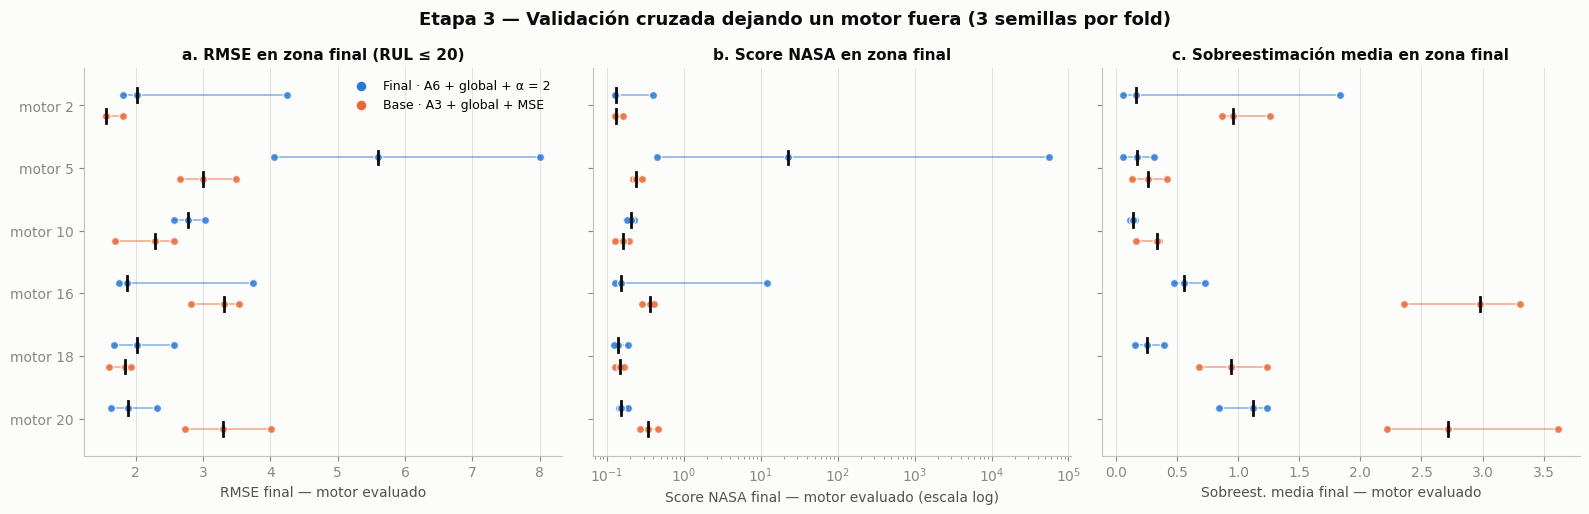

In [31]:
def paired_dotplot(ax, df, metric, rows, groups, colors):
    """Como seed_dotplot, pero con dos configuraciones por fila, desplazadas en vertical."""
    offs = np.linspace(0.17, -0.17, len(groups))
    for i, r in enumerate(rows):
        y0 = len(rows) - 1 - i
        for off, g in zip(offs, groups):
            v = df[(df["unidad"] == r) & (df["config"] == g)][metric].values
            if not len(v):
                continue
            ax.plot([v.min(), v.max()], [y0 + off] * 2, color=colors[g], lw=1.3, alpha=0.5, zorder=2)
            ax.scatter(v, [y0 + off] * len(v), s=34, color=colors[g], alpha=0.85,
                       edgecolor=SURFACE, linewidth=1, zorder=3)
            ax.plot([np.median(v)] * 2, [y0 + off - 0.11, y0 + off + 0.11], color=INK, lw=2, zorder=4)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([f"motor {r}" for r in rows[::-1]])
    ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.grid(axis="y", visible=False)


_units = [int(u) for u in CV_UNITS]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)
for ax, metric, title in ((axes[0], "RMSE final", "a. RMSE en zona final (RUL ≤ 20)"),
                          (axes[1], "Score NASA final", "b. Score NASA en zona final"),
                          (axes[2], "Sobreest. media final", "c. Sobreestimación media en zona final")):
    paired_dotplot(ax, cv_df, metric, _units, ["final", "base"], CFG_COLORS)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} — motor evaluado")
# El score NASA es exponencial: unas pocas predicciones extremas lo llevan a miles, así que
# este panel usa escala logarítmica para no aplastar el resto
axes[1].set_xscale("log")
axes[1].set_xlabel("Score NASA final — motor evaluado (escala log)")
for g in ("final", "base"):
    axes[0].scatter([], [], s=34, color=CFG_COLORS[g], label=CFG_LABELS[g])   # solo para la leyenda
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Etapa 3 — Validación cruzada dejando un motor fuera (3 semillas por fold)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa3_validacion_cruzada.png"), dpi=160, bbox_inches="tight")
plt.show()

## 3.5 Resultados en el conjunto de prueba oficial

Motores 11, 14 y 15. Se reportan tres configuraciones de la partición oficial con 5
semillas, para separar el efecto de cada cambio:

| Configuración | Qué aísla |
|---|---|
| Base · A3 + global + MSE | Punto de partida (v01) |
| A6 + global + MSE | Efecto de la arquitectura |
| Final · A6 + global + α elegido | Efecto adicional de la pérdida asimétrica |

El conjunto de prueba se evaluó una única vez, en v02, con decisiones ya tomadas. Aquí se
vuelve a presentar con las mismas corridas; ninguna decisión de v03 depende de él.

In [32]:
TEST_CFGS = {"base": BASE_CFG,
             "final_mse": dict(arch=STAGE1_CHOICE, norm="global", alpha=1.0),
             "final": FINAL_CFG}
if TEST_CFGS["final_mse"] == FINAL_CFG:          # si el α elegido fuera 1, no hay nada que aislar
    del TEST_CFGS["final_mse"]
TEST_LABELS = {"base": CFG_LABELS["base"],
               "final_mse": f"{STAGE1_CHOICE} + global + MSE",
               "final": CFG_LABELS["final"]}
TEST_COLORS = {"base": ARCH_COLORS["A3"], "final_mse": "#86b6ef", "final": "#2a78d6"}

test_records = run_many([dict(**c, seed=s) for c in TEST_CFGS.values() for s in SEEDS], label="  ")
if not SMOKE_TEST:
    # Todas deben venir de disco: el conjunto de prueba no puede haber influido en un entrenamiento
    assert all(r["cached"] for r in test_records), "una corrida de prueba se entrenó en esta etapa"

test_df = records_to_df(test_records, "eval")
# Traducción de (arquitectura, normalización, α) al nombre de la configuración
_inv = {tuple(c[k] for k in ("arch", "norm", "alpha")): n for n, c in TEST_CFGS.items()}
test_df["config"] = test_df.apply(lambda r: _inv[(r["arch"], r["norm"], r["alpha"])], axis=1)
test_df["cfg"] = test_df["config"].map(TEST_LABELS)
test_df.to_csv(os.path.join(OUT_DIR, "prueba_oficial.csv"), index=False, encoding="utf-8-sig")

print("Prueba oficial (motores 11, 14, 15) — mediana [mín. – máx.] sobre 5 semillas")
display(summary_table(test_df, "cfg", MAIN_METRICS + ["% sobreest. final", "RMSE temprana"]))
print("\nRMSE en zona final por motor de prueba")
display(summary_table(test_df, "cfg", ["RMSE final u11", "RMSE final u14", "RMSE final u15"]))

_mt = test_df.groupby("config")[["RMSE final", "Score NASA final", "Sobreest. media final", "RMSE"]].median()
selection["decisiones"]["etapa_3"] = {
    "validacion_cruzada_rmse_final_mediana_por_motor": {
        str(int(u)): {c: round(float(_med_u[("RMSE final", c)].loc[int(u)]), 4) for c in ("final", "base")}
        for u in CV_UNITS},
    "prueba_oficial_mediana": {c: {m: round(float(_mt.loc[c, m]), 4) for m in _mt.columns}
                               for c in TEST_CFGS},
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · alpha=1 · semilla 4 | mejor época 10/15 | caché
  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · alpha=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · alpha=1 · semilla 4 | mejor época 30/30 | caché
  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · alpha=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
-> 15 corridas en 0.0 min (15 desde cach

,cfg,n,RMSE final,Sobreest. media final,Score NASA final,RMSE,Sesgo,% sobreest. final,RMSE temprana
0,Base · A3 + global + MSE,5,2.97 [2.47 – 3.30],2.35 [1.47 – 2.71],0.29 [0.21 – 0.34],6.01 [5.54 – 6.61],3.00 [1.40 – 3.67],86.03 [64.03 – 91.94],7.16 [6.54 – 7.44]
1,A6 + global + MSE,5,2.16 [1.92 – 2.45],1.60 [1.05 – 2.10],0.19 [0.17 – 0.24],5.28 [4.99 – 5.60],1.24 [1.11 – 1.77],82.47 [58.10 – 97.02],6.67 [6.35 – 6.84]
2,Final · A6 + global + α = 2,5,1.78 [1.50 – 1.97],1.00 [0.71 – 1.47],0.14 [0.12 – 0.18],5.34 [4.95 – 5.56],0.19 [-0.65 – 0.46],67.40 [58.85 – 85.66],7.72 [6.79 – 8.25]



RMSE en zona final por motor de prueba


,cfg,n,RMSE final u11,RMSE final u14,RMSE final u15
0,Base · A3 + global + MSE,5,3.45 [2.76 – 3.54],2.23 [1.72 – 3.79],2.13 [2.07 – 2.62]
1,A6 + global + MSE,5,2.33 [2.03 – 2.71],2.25 [1.64 – 2.40],1.71 [1.57 – 1.99]
2,Final · A6 + global + α = 2,5,1.86 [1.39 – 2.20],1.32 [0.84 – 2.43],1.49 [1.35 – 1.73]


## 3.6 Figuras: prueba oficial

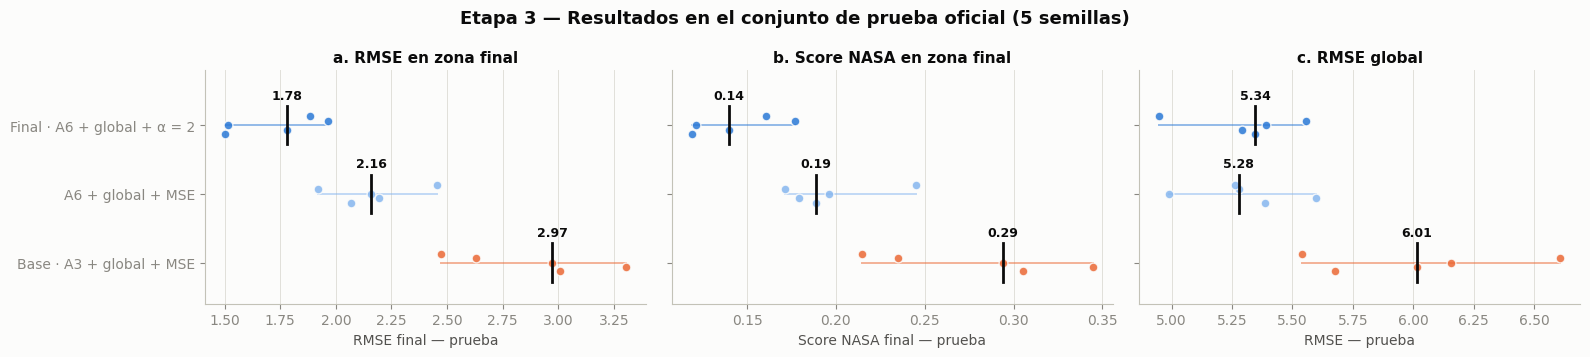

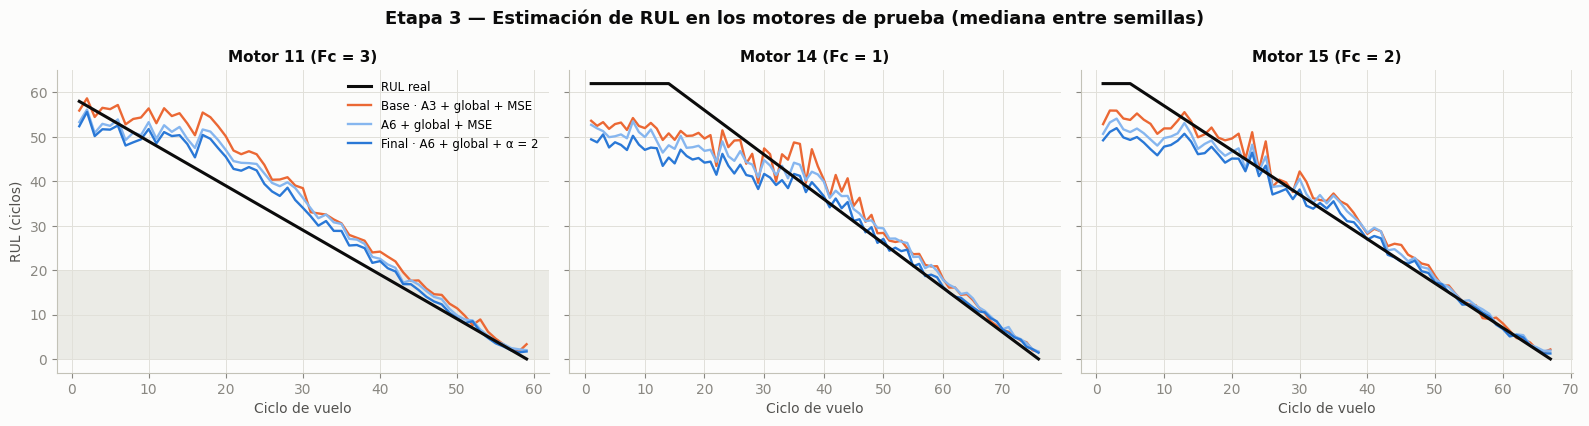

In [33]:
_tcfgs = [TEST_LABELS[c] for c in ("final", "final_mse", "base") if c in TEST_CFGS]
_tcolors = {TEST_LABELS[c]: TEST_COLORS[c] for c in TEST_CFGS}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, metric, title in ((axes[0], "RMSE final", "a. RMSE en zona final"),
                          (axes[1], "Score NASA final", "b. Score NASA en zona final"),
                          (axes[2], "RMSE", "c. RMSE global")):
    seed_dotplot(ax, test_df, metric, _tcfgs, group_col="cfg", colors=_tcolors)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} — prueba")
fig.suptitle("Etapa 3 — Resultados en el conjunto de prueba oficial (5 semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa3_prueba_metricas.png"), dpi=160, bbox_inches="tight")
plt.show()

# Trayectorias de RUL de cada motor de prueba: mediana entre semillas del promedio por ciclo
_, _yt, _mt_meta = build_tensors("global", "oficial")["eval"]
_test_units = sorted(np.unique(_mt_meta[:, 0]))
fig, axes = plt.subplots(1, len(_test_units), figsize=(16, 4.3), sharey=True)
for ax, u in zip(axes, _test_units):
    m = _mt_meta[:, 0] == u
    cyc = np.unique(_mt_meta[m, 1])
    ax.axhspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.plot(cyc, [_yt[m][_mt_meta[m, 1] == c].mean() for c in cyc], color=INK, lw=2.2,
            label="RUL real", zorder=4)
    for name in [c for c in ("base", "final_mse", "final") if c in TEST_CFGS]:
        recs = [r for r in test_records if _inv[(r["arch"], r["norm"], r["alpha"])] == name]
        per_seed = [[r["eval_pred"][m][_mt_meta[m, 1] == c].mean() for c in cyc] for r in recs]
        ax.plot(cyc, np.median(per_seed, axis=0), color=TEST_COLORS[name], lw=1.7,
                label=TEST_LABELS[name], zorder=3)
    # La clase de vuelo Fc se muestra porque los motores 14 y 15 vuelan clases no vistas
    ax.set_title(f"Motor {int(u)} (Fc = {int(np.unique(test['fc'][test['unit'] == u])[0])})")
    ax.set_xlabel("Ciclo de vuelo")
axes[0].set_ylabel("RUL (ciclos)")
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Etapa 3 — Estimación de RUL en los motores de prueba (mediana entre semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa3_prueba_trayectorias.png"), dpi=160, bbox_inches="tight")
plt.show()

## 3.7 Discusión

### Prueba oficial: la configuración final gana con claridad

| Configuración | RMSE final | Score NASA final | Sesgo | RMSE zona temprana |
|---|---|---|---|---|
| Base · A3 + global + MSE | 2,97 [2,47 – 3,30] | 0,29 | +3,00 | 7,16 |
| A6 + global + MSE | 2,16 [1,92 – 2,45] | 0,19 | +1,24 | 6,67 |
| **Final · A6 + global + α = 2** | **1,78** [1,50 – 1,97] | **0,14** | **+0,19** | 7,72 |

- **Los rangos no se solapan:** la peor semilla de la configuración final (1,97) es mejor
  que la mejor de la base (2,47).
- **Mejoran los tres motores de prueba**, incluidos el 14 y el 15, de clases de vuelo
  nunca vistas en entrenamiento: motor 11, 3,45 → 1,86; motor 14, 2,23 → 1,32; motor 15,
  2,13 → 1,49.
- **Cada cambio aporta:** la arquitectura reduce el RMSE final de 2,97 a 2,16 y la pérdida
  asimétrica de 2,16 a 1,78. El sesgo optimista desaparece (+3,00 → +0,19).
- **El costo está al inicio de la vida útil:** el error en la zona temprana sube de 6,67 a
  7,72 al agregar la pérdida asimétrica.

### Validación cruzada: la ventaja depende del motor

| Motor | RMSE final, final | RMSE final, base | Sesgo de la base | Resultado |
|---|---|---|---|---|
| 2 | 2,02 [1,80 – 4,25] | 1,55 [1,55 – 1,81] | +2,18 | peor |
| 5 | 5,60 [4,05 – 8,01] | 2,99 [2,66 – 3,48] | −3,71 | peor |
| 10 | 2,78 [2,57 – 3,03] | 2,29 [1,70 – 2,57] | −4,10 | peor |
| 16 | 1,87 [1,75 – 3,74] | 3,31 [2,82 – 3,53] | +3,60 | **mejor** |
| 18 | 2,01 [1,68 – 2,57] | 1,85 [1,60 – 1,93] | −0,30 | peor |
| 20 | 1,89 [1,63 – 2,32] | 3,30 [2,73 – 4,00] | +4,75 | **mejor** |

La configuración final tiene menor RMSE final en solo 2 de 6 motores (7 de 18 pares
motor-semilla). En cambio, **reduce la sobreestimación en la zona final en los 6 motores**
(16 de 18 pares), que es el objetivo de la pérdida asimétrica.

El sesgo de la base explica el patrón. La pérdida asimétrica desplaza las predicciones
hacia abajo: eso corrige donde la base era **optimista** (motores 16 y 20) y perjudica donde
ya era **pesimista** (motores 5 y 10). En el conjunto de prueba la base sobreestima (+3,00),
por eso ahí la ganancia es clara. La excepción es el motor 2: sesgo base positivo, pero
resultado peor, con una semilla atípica (4,25).

**El motor 20 es el único en que la configuración final sigue sobreestimando** (sesgo de
+2,15), aunque mucho menos que la base (+4,75). Es la sobreestimación comentada en la
Reunión 04, y se analiza por régimen de operación en la etapa 4.

### Robustez: predicciones fuera del rango válido

En la validación cruzada, la configuración final produjo 19 ventanas con predicciones a más
de 5 ciclos fuera del rango válido, con un máximo de 190 ciclos cuando el RUL no puede
superar 62. La base no produjo ninguna. La causa probable es que A6 no tiene ninguna capa
que acote su salida, mientras que el LSTM de A3 acota sus estados internos con `tanh`.

Recortar las predicciones al rango válido solo cambia el motor 5 (RMSE final 5,60 → 4,94).
Los valores extremos explican la explosión del score NASA en ese motor, pero no el patrón
general, que se debe al sesgo. Acotar la salida queda como trabajo futuro.

### Conclusión de la etapa

La configuración final es la mejor en validación y en la prueba oficial, con un margen que
ninguna semilla contradice. La validación cruzada matiza el resultado: **la pérdida
asimétrica siempre reduce la sobreestimación**, pero su efecto sobre la precisión depende de
si el modelo tiende a ser optimista o pesimista con cada motor.

# Etapa 4 — Análisis "doble clic": regímenes de operación

Esta sección profundiza en los resultados ya presentados; no modifica la configuración
final ni ninguna decisión anterior. Responde tres pedidos de la Reunión 04:

1. **Definir mejor los regímenes de operación.** En v02 se usó k-means, que eligió solo 2
   grupos. Aquí se comparan k-means, **DBSCAN** y **Spectral Clustering**, y se contrastan
   con una referencia física: las **fases de vuelo** (ascenso, nivelado, descenso).
2. **Analizar el error del modelo por régimen.**
3. **Explicar la sobreestimación del motor 20.**

**Qué agrupa cada método:**

- **k-means:** divide los datos en K grupos alrededor de K centros, asignando cada punto al
  centro más cercano. Tiende a formar grupos compactos y de forma esférica.
- **DBSCAN:** forma grupos con las zonas de alta densidad. Un punto pertenece a un grupo si
  tiene al menos `min_samples` vecinos a una distancia menor que `eps`. No hay que fijar el
  número de grupos, admite formas arbitrarias y marca como **ruido** los puntos aislados.
- **Spectral Clustering:** construye un grafo que conecta cada punto con sus vecinos más
  cercanos y separa el grafo donde las conexiones son débiles. Encuentra grupos de forma
  arbitraria, pero necesita una matriz de vecindad entre puntos, por lo que no escala a
  cientos de miles de registros.

**Protocolo:**

- Se agrupan las 4 condiciones de vuelo W, estandarizadas con los motores de entrenamiento.
- Los tres métodos se ajustan sobre la **misma submuestra de 8.000 registros** de
  entrenamiento. Después, cada registro de todos los motores se asigna al grupo de sus 15
  vecinos más cercanos de la submuestra (clasificador kNN).
- Calidad del agrupamiento: **silueta** (de −1 a 1; mayor es mejor: cada punto está más
  cerca de su grupo que del grupo vecino) y **Davies-Bouldin** (mayor o igual a 0; menor es
  mejor: grupos compactos y separados). Sentido físico: **índice de Rand ajustado** con las
  fases de vuelo (1 = coincidencia perfecta, 0 = coincidencia al azar).
- Regla fijada antes de ver los resultados: el análisis de error se hace **por fase de
  vuelo** y **por el agrupamiento de mayor silueta**.
- El conjunto de prueba se usa aquí solo para describir errores, no para decidir nada.

## 4.1 Datos y fases de vuelo

La fase de cada registro se obtiene de la tasa de cambio de la altitud dentro de su vuelo:
**ascenso** si sube más de 10 pies por paso de 10 s (60 pies por minuto), **descenso** si
baja más que eso, y **nivelado** en otro caso. La tasa se suaviza con una mediana móvil de
5 pasos para que el ruido no cambie la fase de un registro a otro.

Se habla de vuelo **nivelado** y no de crucero porque los perfiles de N-CMAPSS incluyen
tramos horizontales a altitudes intermedias, no solo a la altitud máxima.

**Por qué 10 pies por paso.** En N-CMAPSS los ascensos y descensos son lentos, de unos 20 a
80 pies por paso (120 a 480 pies por minuto), mientras que en vuelo nivelado la tasa está
prácticamente en cero. Un primer intento con 100 pies por paso, un valor típico de la
aviación comercial real, clasificaba el 98 % del tiempo como nivelado, lo que no
corresponde a los perfiles. La tabla de sensibilidad de esta sección muestra que la
clasificación casi no cambia entre 5 y 20 pies por paso; 10 está en medio de esa zona.

In [34]:
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

N_W = len(var_names["W"])            # las primeras 4 columnas son W
PHASE_NAMES = ["Ascenso", "Nivelado", "Descenso"]
PHASE_COLORS = {"Ascenso": "#eb6834", "Nivelado": "#2a78d6", "Descenso": "#1baf7a"}
PHASE_TH = 10.0                      # pies por paso de 10 s (60 pies por minuto)
CLUSTER_SAMPLE = 8000                # tamaño de la submuestra para ajustar los métodos
KNN_ASSIGN = 15                      # vecinos para asignar cada registro a un grupo


def flight_bounds(d):
    """Límites [inicio, fin) de cada vuelo: segmentos contiguos con el mismo (motor, ciclo)."""
    key = np.stack([d["unit"], d["cycle"]], axis=1)
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    return np.concatenate([[0], np.where(change)[0] + 1, [len(d["unit"])]])


def climb_rate(d):
    """Tasa de cambio de la altitud de cada registro (pies por paso), suavizada dentro de su vuelo."""
    alt = d["features"][:, 0]                         # altitud, en pies
    rate = np.zeros(len(alt))
    b = flight_bounds(d)
    for s, e in zip(b[:-1], b[1:]):
        if e - s < 3:
            continue
        r = np.gradient(alt[s:e])                     # diferencia entre pasos vecinos
        rate[s:e] = pd.Series(r).rolling(5, center=True, min_periods=1).median().values
    return rate


def flight_phases(d, th=PHASE_TH):
    """Fase de vuelo de cada registro: 0 = ascenso, 1 = nivelado, 2 = descenso."""
    rate = climb_rate(d)
    phase = np.ones(len(rate), dtype=int)             # por defecto, nivelado
    phase[rate > th] = 0
    phase[rate < -th] = 2
    return phase


# Sensibilidad al umbral: fracción de registros de dev en cada fase
_rate_dev = climb_rate(dev)
print("Sensibilidad al umbral (registros de dev):")
for th in (2, 5, 10, 20, 50, 100):
    print(f"   {th:>3} pies/paso ({6 * th:>3} pies/min): ascenso {100 * np.mean(_rate_dev > th):5.1f} % | "
          f"descenso {100 * np.mean(_rate_dev < -th):5.1f} %"
          f"{'   (elegido)' if th == PHASE_TH else ''}")

phase_dev, phase_test = flight_phases(dev), flight_phases(test)

# Estandarización de W con los registros de entrenamiento (sin fuga de información)
_tr = np.isin(dev["unit"], TRAIN_UNITS)
w_scaler = StandardScaler().fit(dev["features"][_tr, :N_W])
Wz_dev = w_scaler.transform(dev["features"][:, :N_W])
Wz_test = w_scaler.transform(test["features"][:, :N_W])

# Submuestra común para los tres métodos
SUB = np.random.default_rng(0).choice(np.where(_tr)[0], size=CLUSTER_SAMPLE, replace=False)
Xs = Wz_dev[SUB]

print("\nFracción de registros por fase de vuelo (entrenamiento):")
for p, name in enumerate(PHASE_NAMES):
    print(f"   {name:<9} {100 * np.mean(phase_dev[_tr] == p):5.1f} %")

Sensibilidad al umbral (registros de dev):
     2 pies/paso ( 12 pies/min): ascenso  33.3 % | descenso  26.0 %
     5 pies/paso ( 30 pies/min): ascenso  30.8 % | descenso  23.2 %
    10 pies/paso ( 60 pies/min): ascenso  30.3 % | descenso  22.6 %   (elegido)
    20 pies/paso (120 pies/min): ascenso  28.7 % | descenso  22.1 %
    50 pies/paso (300 pies/min): ascenso  11.2 % | descenso  15.1 %
   100 pies/paso (600 pies/min): ascenso   0.4 % | descenso   1.2 %



Fracción de registros por fase de vuelo (entrenamiento):
   Ascenso    30.3 %
   Nivelado   47.0 %
   Descenso   22.7 %


## 4.2 Ajuste de los tres métodos

- **k-means y Spectral Clustering:** se prueba K = 2 a 6 y se elige el de mayor silueta.
  Spectral usa un grafo de 15 vecinos más cercanos.
- **DBSCAN:** `min_samples = 2 × dimensiones = 8` (regla habitual). `eps` se calibra con el
  **gráfico de distancia al k-ésimo vecino**: se ordenan de menor a mayor las distancias de
  cada punto a su octavo vecino, y `eps` se ubica en el **codo** de esa curva, donde la
  distancia empieza a crecer bruscamente (los puntos a la derecha del codo son los
  aislados). El codo se detecta como el punto más alejado de la recta que une el primer y
  el último punto de la curva. Se informan también 0,75 y 1,5 veces ese valor para ver la
  sensibilidad.

In [35]:
def partition_quality(X, labels):
    """Silueta y Davies-Bouldin, sin contar el ruido de DBSCAN (etiqueta -1)."""
    m = labels >= 0
    if len(np.unique(labels[m])) < 2:                  # con un solo grupo no se pueden calcular
        return np.nan, np.nan
    sil = silhouette_score(X[m], labels[m], sample_size=min(5000, m.sum()), random_state=0)
    return float(sil), float(davies_bouldin_score(X[m], labels[m]))


cl_rows, LABELS = [], {}             # tabla de resultados; etiquetas elegidas de cada método

# --- k-means: K de 2 a 6 ---
for k in range(2, 7):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(Xs)
    sil, db = partition_quality(Xs, lab)
    cl_rows.append({"Método": "k-means", "Parámetro": f"K = {k}", "Grupos": k, "Ruido %": 0.0,
                    "Silueta": sil, "Davies-Bouldin": db,
                    "Rand ajustado vs. fases": adjusted_rand_score(phase_dev[SUB], lab), "_lab": lab})

# --- Spectral Clustering: K de 2 a 6 ---
for k in range(2, 7):
    lab = SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=15,
                             assign_labels="cluster_qr", random_state=0).fit_predict(Xs)
    sil, db = partition_quality(Xs, lab)
    cl_rows.append({"Método": "Spectral", "Parámetro": f"K = {k}", "Grupos": k, "Ruido %": 0.0,
                    "Silueta": sil, "Davies-Bouldin": db,
                    "Rand ajustado vs. fases": adjusted_rand_score(phase_dev[SUB], lab), "_lab": lab})

# --- DBSCAN: eps desde el codo del gráfico de distancia al k-ésimo vecino ---
MIN_SAMPLES = 2 * N_W
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs).kneighbors(Xs)[0][:, -1])
# Codo: punto de la curva más alejado de la recta entre sus extremos (coordenadas normalizadas)
_x = np.linspace(0, 1, len(kdist))
_y = (kdist - kdist[0]) / (kdist[-1] - kdist[0])
knee = int(np.argmax(np.abs(_y - _x)))          # distancia vertical a la recta y = x
EPS_KNEE = float(kdist[knee])
for factor in (0.75, 1.0, 1.5):
    eps = EPS_KNEE * factor
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Xs)
    sil, db = partition_quality(Xs, lab)
    cl_rows.append({"Método": "DBSCAN", "Parámetro": f"eps = {eps:.3f} ({factor:g} × codo)",
                    "Grupos": len(np.unique(lab[lab >= 0])), "Ruido %": 100 * np.mean(lab < 0),
                    "Silueta": sil, "Davies-Bouldin": db,
                    "Rand ajustado vs. fases": adjusted_rand_score(phase_dev[SUB], lab), "_lab": lab,
                    "_factor": factor})

cl_df = pd.DataFrame(cl_rows)
print(cl_df.drop(columns=["_lab", "_factor"], errors="ignore").round(3).to_string(index=False))

# Configuración elegida de cada método: mayor silueta en k-means y Spectral; el codo en DBSCAN
for method in ("k-means", "Spectral"):
    best = cl_df[cl_df["Método"] == method].sort_values("Silueta", ascending=False).iloc[0]
    LABELS[method] = best
LABELS["DBSCAN"] = cl_df[(cl_df["Método"] == "DBSCAN") & (cl_df["_factor"] == 1.0)].iloc[0]

summary_cl = pd.DataFrame([{k: v for k, v in LABELS[m].items() if not k.startswith("_")}
                           for m in ("k-means", "DBSCAN", "Spectral")])
print("\nConfiguración elegida de cada método:")
print(summary_cl.round(3).to_string(index=False))

# Regla fijada de antemano: el análisis de error usa el agrupamiento de mayor silueta
BEST_METHOD = summary_cl.sort_values("Silueta", ascending=False)["Método"].iloc[0]
print(f"\nAgrupamiento usado en el análisis de error (mayor silueta): {BEST_METHOD}")

  Método                 Parámetro  Grupos  Ruido %  Silueta  Davies-Bouldin  Rand ajustado vs. fases
 k-means                     K = 2       2    0.000    0.509           0.773                    0.109
 k-means                     K = 3       3    0.000    0.383           0.977                    0.126
 k-means                     K = 4       4    0.000    0.380           0.953                    0.181
 k-means                     K = 5       5    0.000    0.397           0.867                    0.235
 k-means                     K = 6       6    0.000    0.393           0.881                    0.245
Spectral                     K = 2       2    0.000    0.445           0.800                    0.108
Spectral                     K = 3       3    0.000    0.387           1.090                    0.342
Spectral                     K = 4       4    0.000    0.275           1.057                    0.171
Spectral                     K = 5       5    0.000    0.240           1.087      

### Calibración y comparación visual

Panel a: gráfico de distancia al k-ésimo vecino de DBSCAN, con el `eps` elegido en el codo.
Panel b: silueta según K para k-means y Spectral. Paneles c–f: la misma submuestra en el
plano Mach–altitud, coloreada por fase de vuelo y por cada método.

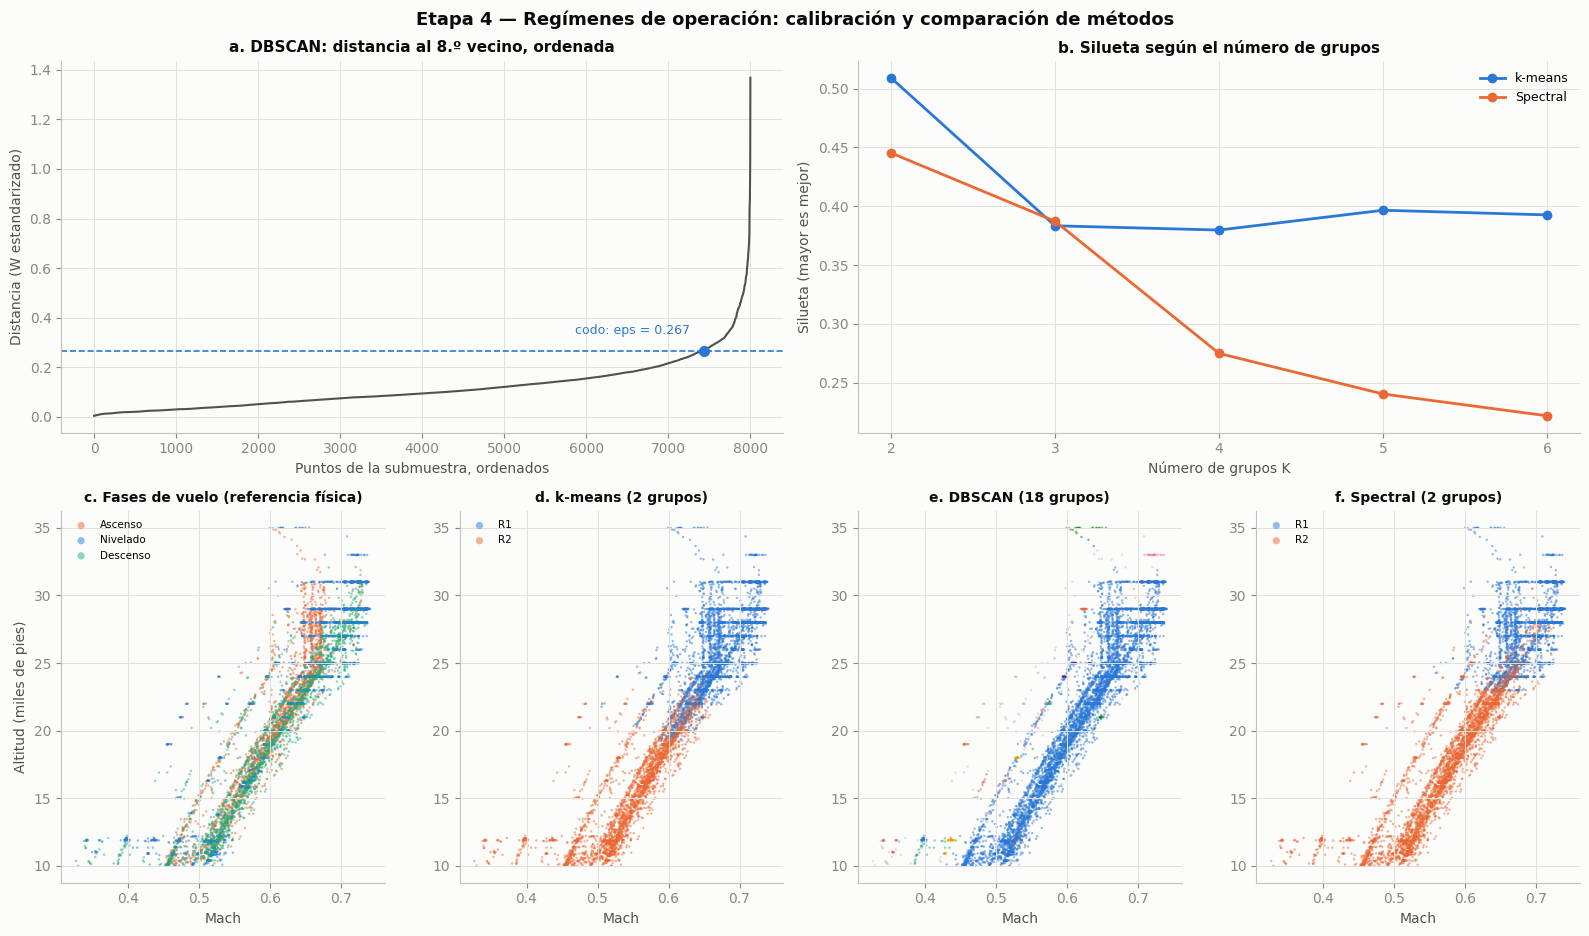

In [36]:
fig = plt.figure(figsize=(16, 9.5))
gs = fig.add_gridspec(2, 4)

ax = fig.add_subplot(gs[0, 0:2])
ax.plot(np.arange(len(kdist)), kdist, color=INK_2, lw=1.5)
ax.axhline(EPS_KNEE, color="#2a78d6", lw=1.2, ls="--")
ax.scatter([knee], [EPS_KNEE], s=50, color="#2a78d6", zorder=3)
ax.annotate(f"codo: eps = {EPS_KNEE:.3f}", (knee, EPS_KNEE), xytext=(-10, 12),
            textcoords="offset points", ha="right", color="#2a78d6", fontsize=9)
ax.set_title(f"a. DBSCAN: distancia al {MIN_SAMPLES}.º vecino, ordenada")
ax.set_xlabel("Puntos de la submuestra, ordenados")
ax.set_ylabel("Distancia (W estandarizado)")

ax = fig.add_subplot(gs[0, 2:4])
for method, color in (("k-means", "#2a78d6"), ("Spectral", "#eb6834")):
    sub = cl_df[cl_df["Método"] == method]
    ax.plot(sub["Grupos"], sub["Silueta"], color=color, lw=2, marker="o", label=method)
ax.set_title("b. Silueta según el número de grupos")
ax.set_xlabel("Número de grupos K")
ax.set_ylabel("Silueta (mayor es mejor)")
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.legend(loc="upper right", fontsize=9)

# Colores por grupo (paleta categórica) y gris para el ruido de DBSCAN
_CL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
_mach, _alt = dev["features"][SUB, 1], dev["features"][SUB, 0] / 1000
# Cuatro paneles: la referencia física (c) y un panel por método (d, e, f)
panels = [("c. Fases de vuelo (referencia física)", phase_dev[SUB], PHASE_NAMES)]
for letter, method in zip("def", ("k-means", "DBSCAN", "Spectral")):
    panels.append((f"{letter}. {method} ({LABELS[method]['Grupos']} grupos)",
                   LABELS[method]["_lab"], None))
for i, (title, lab, names) in enumerate(panels):
    ax = fig.add_subplot(gs[1, i])
    for c in np.unique(lab):
        mm = lab == c
        if c < 0:
            color, name = AXIS, "ruido"
        elif names:
            color, name = PHASE_COLORS[names[c]], names[c]
        else:
            color, name = _CL_COLORS[c % len(_CL_COLORS)], f"R{c + 1}"
        ax.scatter(_mach[mm], _alt[mm], s=3, color=color, alpha=0.5, edgecolor="none", label=name)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Mach")
    if i == 0:
        ax.set_ylabel("Altitud (miles de pies)")
    if len(np.unique(lab)) <= 8:                       # leyenda solo si los grupos son pocos
        ax.legend(loc="upper left", fontsize=7.5, markerscale=3)
fig.suptitle("Etapa 4 — Regímenes de operación: calibración y comparación de métodos",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa4_regimenes.png"), dpi=160, bbox_inches="tight")
plt.show()

## 4.3 Asignación de todos los registros

Cada registro de los 9 motores se asigna al grupo mayoritario entre sus 15 vecinos más
cercanos de la submuestra. En DBSCAN se excluyen los puntos de ruido del clasificador, de
modo que todo registro recibe un grupo. A cada ventana de 30 pasos se le asigna la fase o
el grupo **más frecuente** entre sus registros.

In [37]:
def assign_all(lab):
    """Asigna un grupo a todos los registros de dev y test con un clasificador kNN."""
    m = lab >= 0
    knn = KNeighborsClassifier(n_neighbors=KNN_ASSIGN).fit(Xs[m], lab[m])
    return knn.predict(Wz_dev), knn.predict(Wz_test)


REGIME_DEV, REGIME_TEST = assign_all(LABELS[BEST_METHOD]["_lab"])
REGIME_NAMES = [f"R{c + 1}" for c in range(int(REGIME_DEV.max()) + 1)]


def window_labels(rec_labels, source, units=None):
    """Etiqueta de cada ventana = la más frecuente entre sus 30 registros (mismo orden que _gather)."""
    starts, w_unit, _ = WINDOWS[source]
    m = np.ones(len(starts), bool) if units is None else np.isin(w_unit, units)
    L = rec_labels[starts[m][:, None] + np.arange(WINDOW_SIZE)[None, :]]       # (N, 30)
    counts = np.stack([(L == c).sum(axis=1) for c in range(int(rec_labels.max()) + 1)], axis=1)
    return counts.argmax(axis=1)


# Centro de cada régimen del método elegido, en unidades físicas
_cent = pd.DataFrame(dev["features"][_tr, :N_W], columns=var_names["W"])
_cent["Régimen"] = [REGIME_NAMES[c] for c in REGIME_DEV[_tr]]
_cent["Fase más frecuente"] = [PHASE_NAMES[p] for p in phase_dev[_tr]]
print(f"Regímenes de {BEST_METHOD} (registros de entrenamiento):")
print(_cent.groupby("Régimen").agg(
    registros=("alt", "size"), alt=("alt", "mean"), Mach=("Mach", "mean"), TRA=("TRA", "mean"),
    T2=("T2", "mean"), fase=("Fase más frecuente", lambda s: s.value_counts().index[0])
).round(2).to_string())

Regímenes de k-means (registros de entrenamiento):
         registros           alt  Mach        TRA          T2      fase
Régimen                                                                
R1          216318  26244.810547  0.68  74.900002  463.869995  Nivelado
R2          144139  15163.450195  0.54  58.700001  492.140015  Descenso


## 4.4 Error del modelo por fase de vuelo y por régimen

Para la configuración final y para la base, en validación (motores 18 y 20) y en prueba
(motores 11, 14 y 15). Cada celda es la mediana [mín. – máx.] sobre las 5 semillas.
"RMSE final" es el RMSE restringido a la zona final (RUL ≤ 20) dentro de ese grupo.

In [38]:
RUN_REGIME_ERROR = not SMOKE_TEST   # en la prueba rápida las ventanas están submuestreadas


def group_errors(preds, y, groups, names):
    """Tabla de error por grupo: % de ventanas, RMSE, sesgo y RMSE en la zona final."""
    rows = []
    for g, name in enumerate(names):
        m = groups == g
        if not m.any():
            continue
        fin = m & (y <= FINAL_ZONE)
        rows.append({
            "Grupo": name, "% ventanas": round(100 * m.mean(), 1),
            "RMSE": med_range([rmse(y[m], p[m]) for p in preds]),
            "Sesgo": med_range([np.mean(p[m] - y[m]) for p in preds]),
            "RMSE final": med_range([rmse(y[fin], p[fin]) for p in preds]) if fin.any() else "—",
        })
    return pd.DataFrame(rows)


if RUN_REGIME_ERROR:
    _, y_val, meta_val = build_tensors("global", "oficial")["val"]
    _, y_tst, meta_tst = build_tensors("global", "oficial")["eval"]

    # Predicciones de cada semilla para las dos configuraciones
    PRED = {
        ("final", "val"): [r["val_pred"] for r in stage2 if r["alpha"] == STAGE2_CHOICE],
        ("base", "val"): [r["val_pred"] for r in stage1 if r["arch"] == "A3"],
        ("final", "test"): [r["eval_pred"] for r in test_records
                            if _inv[(r["arch"], r["norm"], r["alpha"])] == "final"],
        ("base", "test"): [r["eval_pred"] for r in test_records
                           if _inv[(r["arch"], r["norm"], r["alpha"])] == "base"],
    }
    # Fase y régimen de cada ventana, en el mismo orden que las predicciones
    GROUPS = {
        ("fase", "val"): window_labels(phase_dev, "dev", VAL_UNITS),
        ("fase", "test"): window_labels(phase_test, "test"),
        ("regimen", "val"): window_labels(REGIME_DEV, "dev", VAL_UNITS),
        ("regimen", "test"): window_labels(REGIME_TEST, "test"),
    }
    Y = {"val": y_val, "test": y_tst}

    for kind, names in (("fase", PHASE_NAMES), ("regimen", REGIME_NAMES)):
        for split in ("val", "test"):
            print(f"\n{'Fase de vuelo' if kind == 'fase' else 'Régimen ' + BEST_METHOD} · "
                  f"{'validación' if split == 'val' else 'prueba'}")
            for cfg in ("final", "base"):
                t = group_errors(PRED[(cfg, split)], Y[split], GROUPS[(kind, split)], names)
                t.insert(0, "Config.", "Final" if cfg == "final" else "Base")
                print(t.to_string(index=False))


Fase de vuelo · validación
Config.    Grupo  % ventanas               RMSE                 Sesgo         RMSE final
  Final  Ascenso        30.1 4.17 [4.03 – 5.02] -1.21 [-2.41 – -0.48] 1.55 [1.40 – 1.95]
  Final Nivelado        48.1 4.27 [4.15 – 4.45]  -0.71 [-1.02 – 0.09] 1.66 [1.39 – 2.22]
  Final Descenso        21.8 5.33 [5.00 – 6.63]  -0.75 [-2.71 – 0.79] 2.31 [1.99 – 2.91]
Config.    Grupo  % ventanas               RMSE               Sesgo         RMSE final
   Base  Ascenso        30.1 4.54 [3.99 – 5.81] 1.04 [-0.52 – 2.31] 2.10 [1.68 – 2.39]
   Base Nivelado        48.1 4.79 [4.58 – 5.38]  1.54 [0.91 – 2.55] 2.39 [2.08 – 2.86]
   Base Descenso        21.8 5.26 [4.92 – 5.67]  1.44 [0.26 – 2.87] 3.47 [2.35 – 3.84]

Fase de vuelo · prueba
Config.    Grupo  % ventanas               RMSE                Sesgo         RMSE final
  Final  Ascenso        30.0 4.81 [4.75 – 5.67] -0.10 [-1.85 – 0.22] 1.48 [1.14 – 1.61]
  Final Nivelado        46.1 5.11 [4.68 – 5.48]   0.60 [0.19 – 0.96]

## 4.5 Motor 20: perfil de operación y sesgo por fase

Primero se compara el perfil de operación de los 9 motores: qué fracción del tiempo pasa
cada uno en cada fase, cuánto duran sus vuelos y a qué altitud cruzan. Después se compara
el sesgo de la configuración final en los motores 18 y 20, separado por fase de vuelo.

In [39]:
prof_rows = []
for part, d, ph in (("dev", dev, phase_dev), ("test", test, phase_test)):
    for u in np.unique(d["unit"]):
        m = d["unit"] == u
        n_cycles = len(np.unique(d["cycle"][m]))
        # Altitud máxima de cada vuelo del motor; su mediana resume la altitud de crucero
        max_alt = pd.Series(d["features"][m, 0]).groupby(d["cycle"][m]).max()
        row = {"Partición": part, "Motor": int(u), "Fc": int(np.unique(d["fc"][m])[0]),
               # Cada registro equivale a 10 s de vuelo
               "Vuelo medio (min)": round(m.sum() / n_cycles * SAMPLE_STEP / 60, 1),
               "Altitud de crucero (pies)": int(max_alt.median())}
        for p, name in enumerate(PHASE_NAMES):
            row[f"% {name.lower()}"] = round(100 * np.mean(ph[m] == p), 1)
        prof_rows.append(row)
profile = pd.DataFrame(prof_rows)
print(profile.to_string(index=False))

if RUN_REGIME_ERROR:
    print("\nSesgo de la configuración final por fase de vuelo (validación, mediana sobre semillas):")
    rows = []
    for u in VAL_UNITS:
        mu = meta_val[:, 0] == u
        for p, name in enumerate(PHASE_NAMES):
            m = mu & (GROUPS[("fase", "val")] == p)
            fin = m & (y_val <= FINAL_ZONE)
            rows.append({"Motor": int(u), "Fase": name, "Ventanas": int(m.sum()),
                         "Sesgo": med_range([np.mean(pr[m] - y_val[m]) for pr in PRED[("final", "val")]]),
                         "Sesgo zona final": med_range([np.mean(pr[fin] - y_val[fin])
                                                        for pr in PRED[("final", "val")]]) if fin.any() else "—"})
    print(pd.DataFrame(rows).to_string(index=False))

Partición  Motor  Fc  Vuelo medio (min)  Altitud de crucero (pies)  % ascenso  % nivelado  % descenso
      dev      2   3              189.6                      28015       32.0        45.5        22.6
      dev      5   3              193.5                      28018       29.4        47.7        22.9
      dev     10   3              193.6                      28018       30.2        46.3        23.5
      dev     16   3              202.5                      28018       29.9        48.6        21.5
      dev     18   3              209.1                      28027       30.8        46.4        22.8
      dev     20   3              194.0                      27039       29.4        48.4        22.2
     test     11   3              187.4                      27017       30.5        46.6        22.9
     test     14   1               34.4                      11928       17.4        58.8        23.8
     test     15   2              107.8                      22999       34.4     

### Sesgo y vida total de cada motor

Hipótesis: el modelo aprende una trayectoria de degradación "promedio". Un motor que se
degrada más rápido que el promedio, y por lo tanto vive menos ciclos, recibiría
predicciones optimistas (sobreestimación); uno que vive más, predicciones pesimistas.

Se contrasta con la validación cruzada de la etapa 3, donde cada uno de los 6 motores de
desarrollo fue evaluado sin haberse usado para entrenar. La medida es la **correlación de
Spearman**, que evalúa si dos variables crecen o decrecen juntas en el mismo orden (−1:
relación inversa perfecta, 0: sin relación, 1: relación directa perfecta). Con solo 6
motores, el resultado debe leerse como indicio y no como prueba.

In [40]:
from scipy.stats import spearmanr

# Vida total de cada motor de desarrollo: su último ciclo de vuelo registrado
life = pd.Series({int(u): int(dev["cycle"][dev["unit"] == u].max()) for u in CV_UNITS},
                 name="Vida total (ciclos)")
# Sesgo mediano entre semillas de cada configuración, por motor evaluado
bias_cv = cv_df.groupby(["unidad", "config"])["Sesgo"].median().unstack("config")
life_tab = pd.concat([life, bias_cv.rename(columns={"base": "Sesgo base", "final": "Sesgo final"})],
                     axis=1).sort_values("Vida total (ciclos)")
print(life_tab.round(2).to_string())
for cfg in ("base", "final"):
    rho, _ = spearmanr(life_tab["Vida total (ciclos)"], life_tab[f"Sesgo {cfg}"])
    print(f"Correlación de Spearman entre vida total y sesgo ({cfg}): {rho:+.2f}")

    Vida total (ciclos)  Sesgo base  Sesgo final
16                   63        3.60        -0.19
20                   66        4.75         2.15
18                   71       -0.29        -3.71
2                    75        2.18        -2.15
10                   82       -4.10        -6.18
5                    89       -3.71        -8.06
Correlación de Spearman entre vida total y sesgo (base): -0.83
Correlación de Spearman entre vida total y sesgo (final): -0.89


### Figura: perfil de operación, sesgo por fase y sesgo según vida total

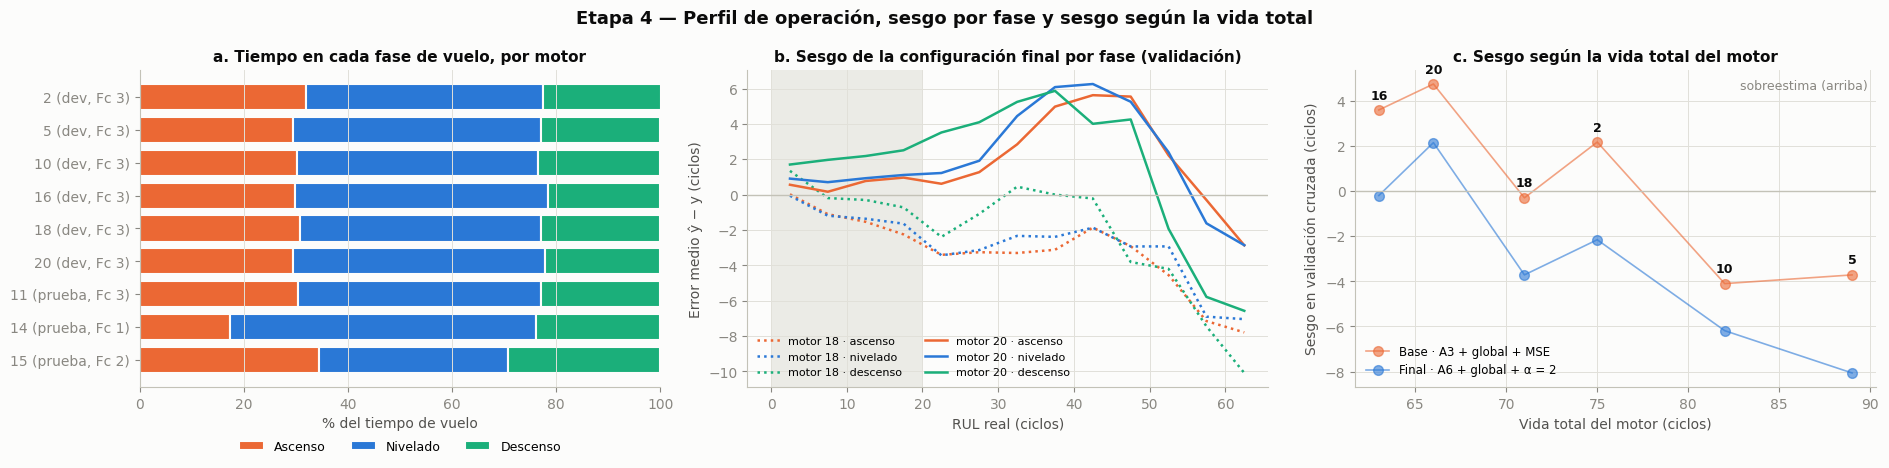

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

# Panel a: fracción del tiempo en cada fase, por motor (barras apiladas horizontales)
ax = axes[0]
_lbl = [f"{r['Motor']} ({'prueba' if r['Partición'] == 'test' else 'dev'}, Fc {r['Fc']})"
        for _, r in profile.iterrows()]
left = np.zeros(len(profile))
for name in PHASE_NAMES:
    vals = profile[f"% {name.lower()}"].values
    ax.barh(_lbl, vals, left=left, color=PHASE_COLORS[name], edgecolor=SURFACE, linewidth=1.5,
            label=name)
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% del tiempo de vuelo")
ax.set_title("a. Tiempo en cada fase de vuelo, por motor")
# Leyenda debajo del panel, para no tapar las barras
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9)
ax.grid(axis="y", visible=False)

# Panel b: sesgo medio de la configuración final por RUL real, en cada fase, motores 18 y 20
ax = axes[1]
if RUN_REGIME_ERROR:
    edges = np.arange(0, RUL_MAX + 5, 5)
    centers = (edges[:-1] + edges[1:]) / 2
    for u, ls in ((18.0, ":"), (20.0, "-")):
        for p, name in enumerate(PHASE_NAMES):
            m = (meta_val[:, 0] == u) & (GROUPS[("fase", "val")] == p)
            if m.sum() < 50:
                continue
            d = np.median([pr[m] - y_val[m] for pr in PRED[("final", "val")]], axis=0)
            idx = np.clip(np.digitize(y_val[m], edges) - 1, 0, len(centers) - 1)
            curve = [d[idx == k].mean() if np.sum(idx == k) >= 10 else np.nan for k in range(len(centers))]
            ax.plot(centers, curve, color=PHASE_COLORS[name], ls=ls, lw=1.8,
                    label=f"motor {int(u)} · {name.lower()}")
    ax.axhline(0, color=AXIS, lw=1)
    ax.axvspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.set_xlabel("RUL real (ciclos)")
    ax.set_ylabel("Error medio ŷ − y (ciclos)")
    ax.set_title("b. Sesgo de la configuración final por fase (validación)")
    ax.legend(loc="lower left", fontsize=8, ncol=2)

# Panel c: sesgo en la validación cruzada según la vida total de cada motor
ax = axes[2]
for cfg in ("base", "final"):
    ax.plot(life_tab["Vida total (ciclos)"], life_tab[f"Sesgo {cfg}"], color=CFG_COLORS[cfg],
            lw=1.2, alpha=0.6, marker="o", ms=7, label=CFG_LABELS[cfg])
for u, row in life_tab.iterrows():                    # rótulo de cada motor sobre la base
    ax.annotate(f"{u}", (row["Vida total (ciclos)"], row["Sesgo base"]), xytext=(0, 8),
                textcoords="offset points", ha="center", color=INK, fontsize=9, fontweight="bold")
ax.axhline(0, color=AXIS, lw=1)
ax.set_xlabel("Vida total del motor (ciclos)")
ax.set_ylabel("Sesgo en validación cruzada (ciclos)")
ax.set_title("c. Sesgo según la vida total del motor")
ax.annotate("sobreestima (arriba)", (1, 1), xycoords="axes fraction", xytext=(-6, -14),
            textcoords="offset points", ha="right", color=MUTED, fontsize=9)
ax.legend(loc="lower left", fontsize=8.5)
fig.suptitle("Etapa 4 — Perfil de operación, sesgo por fase y sesgo según la vida total",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa4_motor20.png"), dpi=160, bbox_inches="tight")
plt.show()

## 4.6 Discusión

### Ningún método de agrupamiento recupera las fases de vuelo

| Método (configuración elegida) | Grupos | Silueta | Davies-Bouldin | Rand ajustado vs. fases |
|---|---|---|---|---|
| k-means (K = 2) | 2 | **0,51** | **0,77** | 0,11 |
| Spectral (K = 2) | 2 | 0,45 | 0,80 | 0,11 |
| DBSCAN (eps en el codo) | 18, con 3,5 % de ruido | −0,48 | 1,21 | 0,01 |

- **k-means** sigue siendo el de mejor silueta, con los mismos dos grupos que en v02: un
  régimen alto (unos 26 mil pies, Mach 0,68) y uno bajo (unos 15 mil pies, Mach 0,54). Son
  **franjas de altitud y velocidad, no fases de vuelo.**
- **Spectral Clustering** con K = 3 es el que más se acerca a las fases (Rand ajustado 0,34),
  pero su silueta baja a 0,39, y con la regla de la silueta queda en K = 2.
- **DBSCAN** no es adecuado para estos datos. Los registros forman trayectorias continuas y
  franjas horizontales (las altitudes de vuelo nivelado), sin zonas densas separadas por
  vacíos. El resultado es un gran grupo, muchos fragmentos y una silueta negativa, además de
  una fuerte sensibilidad a `eps`: 34, 18 o 9 grupos según el valor.

**La razón de fondo no es el algoritmo, sino lo que se agrupa.** El panel c de la figura de
regímenes muestra que, en el plano Mach–altitud, los registros de ascenso y de descenso se
superponen: un avión pasa por las mismas condiciones al subir y al bajar. Las fases se
distinguen por **cómo cambian** las condiciones (la tasa de ascenso), no por sus valores en
un instante. Por eso ningún algoritmo que agrupe solo los valores instantáneos de W puede
recuperarlas. Para definir regímenes con sentido físico habría que incluir variables
dinámicas, como la tasa de cambio de la altitud o del empuje.

### Error del modelo por fase de vuelo

| Fase | % ventanas | RMSE final (validación), final / base | RMSE final (prueba), final / base |
|---|---|---|---|
| Ascenso | 30 % | 1,55 / 2,10 | 1,48 / 2,76 |
| Nivelado | 47 % | 1,66 / 2,39 | 1,53 / 3,15 |
| Descenso | 22–24 % | 2,31 / 3,47 | 2,22 / 3,01 |

- **El descenso es la fase más difícil** para ambas configuraciones, en validación y en
  prueba. Es la fase en que las condiciones de operación cambian más rápido (empuje bajo,
  altitud que cae), lo que coincide con lo que el profesor anticipó sobre la complejidad del
  régimen de operación.
- **La configuración final mejora a la base en las tres fases**, y la base sobreestima en
  todas (sesgo de +1,8 a +3,5 ciclos en prueba).
- Con los regímenes de k-means, el régimen bajo (R2) tiene más error que el alto (RMSE de
  validación 5,12 frente a 4,18), en línea con que incluye buena parte de los ascensos y
  descensos.

### Motor 20: la sobreestimación sigue a la vida total, no al régimen

**El perfil de operación del motor 20 es prácticamente igual al de los demás motores de
desarrollo:** clase de vuelo 3, vuelos de 194 minutos, 29 % de ascenso, 48 % nivelado y 22 %
de descenso. La única diferencia visible es una altitud de crucero algo menor (27.039 pies
frente a unos 28.020). Además, su sesgo es positivo en las **tres** fases (+1,6 a +1,8
ciclos), mientras que el del motor 18 es negativo en las tres (−2,8 a −3,5). La
sobreestimación no se concentra en una fase ni en un régimen: es un desplazamiento de todo
el motor.

Lo que sí la explica es la **vida total**. En la validación cruzada, el sesgo de cada motor
disminuye a medida que su vida aumenta:

| Motor | Vida total (ciclos) | Sesgo base | Sesgo final |
|---|---|---|---|
| 16 | 63 | +3,60 | −0,19 |
| 20 | 66 | +4,75 | +2,15 |
| 18 | 71 | −0,29 | −3,71 |
| 2 | 75 | +2,18 | −2,15 |
| 10 | 82 | −4,10 | −6,18 |
| 5 | 89 | −3,71 | −8,06 |

La correlación de Spearman entre vida total y sesgo es **−0,83** para la base y **−0,89**
para la configuración final. La interpretación: el modelo aprende una trayectoria de
degradación "promedio". Un motor que se degrada más rápido que ese promedio, y por eso
vive menos, recibe predicciones optimistas; uno que se degrada más lento, pesimistas. El
motor 20 es el segundo de vida más corta (66 ciclos), y por eso se sobreestima.

Esto también explica el patrón de la etapa 3: la pérdida asimétrica desplaza todas las
predicciones hacia abajo, lo que corrige a los motores de vida corta (16 y 20) y perjudica
a los de vida larga (5 y 10).

**Cautelas.** Son 6 motores, así que la correlación es un indicio fuerte, no una prueba. Y
la vida total solo se conoce al final: no se puede usar para corregir las predicciones de
un motor en operación. Un modelo que estimara la velocidad de degradación del motor a
partir de su historial es una línea natural de trabajo futuro.

# Etapa 5 — Documentación

Esta etapa no tiene código: produce cuatro documentos en la misma carpeta del notebook.

| Documento | Contenido | Pedido de la Reunión 04 |
|---|---|---|
| `Metodologia_IA.md` | Herramientas, división de roles, flujo de trabajo, salvaguardas, registro de errores de la IA y un párrafo sugerido para la memoria. Marco de referencia: declaración de COPE (2023) sobre autoría y herramientas de IA | Documentar la metodología de uso de IA |
| `Guia_Estudio.md` | Recorrido del dato por la red con la forma de cada tensor y el cálculo de parámetros; convolución, LSTM, promedio temporal y atención; atención por producto punto de *Attention Is All You Need*; pérdida y expectiles; preguntas de autoevaluación | Estudiar el código y la teoría |
| `Diagramas.md` | Diez diagramas Mermaid, con la forma del tensor en cada bloque | Diagramas claros; aclarar la convolución "32 → 64" |
| `Preparacion_Defensa.md` | Preguntas probables con sus respuestas, limitaciones y pendientes antes de la defensa | Preparar la sesión de preguntas tipo examen de grado |

## 5.1 Conclusiones de ProjectV03

1. **El código de v03 reproduce exactamente a v02** (diferencia cero en historial y
   predicciones), por lo que sus 96 corridas se reutilizaron.
2. **Con las curvas en un eje común de 30 épocas, A6 converge más lento** que el resto
   (mejor época 16 frente a 7–9), como anticipó el profesor.
3. **La pérdida tiene nombre y respaldo:** pérdida cuadrática asimétrica, de la regresión por
   expectiles (Newey y Powell, 1987; Efron, 1991). La condición de equilibrio de los
   expectiles se cumple aproximadamente en los datos.
4. **La configuración final (A6 + global + α = 2) mejora a la base en la prueba oficial** sin
   excepciones entre semillas (RMSE final 1,78 frente a 2,97), aunque en la validación
   cruzada la ventaja depende del motor.
5. **Agrupar las condiciones de vuelo no recupera las fases de vuelo**, con ningún método:
   ascenso y descenso se superponen en W. Definir regímenes con sentido físico requiere
   variables dinámicas.
6. **El descenso es la fase con más error**, y **la sobreestimación del motor 20 se explica
   por su vida corta**, no por su régimen (correlación de Spearman entre vida y sesgo de
   −0,83 a −0,89).

## 5.2 Trabajo futuro

1. Ablación estricta: tres extractores por dos agregaciones, con bloques idénticos.
2. Acotar la salida del modelo al rango válido de RUL.
3. Regímenes de operación con variables dinámicas (tasa de ascenso, cambios de empuje).
4. Estimar la velocidad de degradación de cada motor a partir de su historial, para corregir
   el sesgo asociado a la vida total.
5. Más subconjuntos de N-CMAPSS, para evaluar el cambio entre clases de vuelo.